# Midterm report: visualizations and figures

**CEE C281 · Colin & Pratiyush · Stages 2–3**

Regenerates every figure and table in the midterm report. Each figure is saved to `reports/midterm/figures/` as PNG (for the report) and PDF (vector).

All simulation results come from the Stage 3 HTML model (`stage3_two_lane_merge/two_lane_merge.html`), run headless through `simtools.run_stage3()`. Seeds are fixed, so rerunning gives the same numbers. Needs Node.js 18+ and `pip install -r requirements.txt`. Runtime about 6 minutes on a laptop with the sweep results cached (about 20 minutes with `RERUN = True`).

| Figure | Report section | What it shows |
|---|---|---|
| Fig 0 | 2.1 | Stage 3 layout with all dimensions, to scale |
| Fig 1 | 1.2 | The three build stages, to scale |
| Fig 2 | 2.3 | IDM car-following: the drawing and the acceleration it produces |
| Fig 3 | 3.2 (H1), 3.3 (H2) | Merge capacity threshold for T = 1.0 and 1.5 s |
| Fig 4 | 3.2 (H1) | Plateau: output versus offered load |
| Fig 5 | 3.2 (H1) | Displacement: ramp demand at q_A = 3,200 veh/h |
| Fig 6 | 3.3 (H2) | Time gap T: people delivered, TET*, hard braking |
| Fig 7 | 3.4 (H3) | Wave speed and braking-pulse amplification |
| Fig 8 | 3.5 (H4) | Meter-wait sweep, q_B = 900 veh/h |
| Fig 9 | 3.6 (H5) | Speed limit vs. throughput and crash risk |
| Fig 10 | 3.7 (H6) | b_safe, acceleration lane and merge location sweeps |
| Fig 11 | 3.7 (H6) | Acceleration lane × meter wait grid |
| Fig 12 | 3.8 (H7) | People delivered with a one-lane crash (0, 0.25, 0.5 h) |
| Fig 13 | 3.8 (H7) | 15 min lane blockage vs. D/D/1 |
| Fig 14 | 3.9 | Ramp queue vs. M/D/1 (verification) |
| Fig 15 | 3.9 | The merge as the bottleneck: x–t diagram and speed profile |
| Fig 16 | 3.9 | Flow–density and speed–flow from detectors vs. IDM equilibrium |
| Fig 17 | 3.9 | Capacity versus conflict exposure for every design tested |

Figures 4–6, 8, 10–12 and 17 come from the hypothesis sweeps in `sweeps.py` (cached in `tables/sweep_*.csv`; set `RERUN = True` to run them again, about 10–15 min).

In [1]:
import sys, time
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, FancyBboxPatch, Polygon

REPO = Path.cwd().resolve()
while not (REPO / "simtools").exists() and REPO != REPO.parent:
    REPO = REPO.parent
sys.path.insert(0, str(REPO))
import simtools as st
from simtools import theory as th

FIG = REPO / "reports" / "midterm" / "figures"; FIG.mkdir(parents=True, exist_ok=True)
TAB = REPO / "reports" / "midterm" / "tables"; TAB.mkdir(parents=True, exist_ok=True)
FT, MPH, KMH = 0.3048, 0.44704, 1.609344
SEEDS = (1, 2, 3)

# one consistent look: colour-blind-safe palette, same fonts everywhere
INK, MUTED, GRID = "#1f2328", "#59636e", "#d0d7de"
C1, C2, C3, C4, C5 = "#0072B2", "#D55E00", "#009E73", "#CC79A7", "#E69F00"
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
                     "axes.labelcolor": INK, "axes.edgecolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
                     "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": GRID, "grid.alpha": .7,
                     "legend.frameon": False, "legend.fontsize": 8.5,
                     # Times New Roman everywhere; Liberation Serif / TeX Gyre Termes are metric-compatible stand-ins where it is not installed
                     "font.family": "serif", "font.serif": ["Times New Roman", "Liberation Serif", "TeX Gyre Termes", "Nimbus Roman", "DejaVu Serif"],
                     "mathtext.fontset": "stix", "pdf.fonttype": 42, "ps.fonttype": 42})
import logging; logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)

def save(fig, name):
    fig.savefig(FIG / f"{name}.png", bbox_inches="tight"); fig.savefig(FIG / f"{name}.pdf", bbox_inches="tight")
    print("saved", (FIG / f"{name}.png").relative_to(REPO))

def warm(det, t=600):
    return det[det.t0 >= t]

CAP_CODE = th.idm_capacity(30*MPH, 1.0, 8*FT, 15*FT)[0]
T0 = time.time()
print(f"IDM capacity at code values: {CAP_CODE:,.0f} veh/h/lane")

IDM capacity at code values: 1,865 veh/h/lane


## Tables: parameters and experimental protocol

In [2]:
# Table 1: final (Stage 3) parameters
p = st.params.table()
def fmt(x, unit):
    if x is None or (isinstance(x, float) and np.isnan(x)): return "–"
    return f"{x:,.2f}".rstrip("0").rstrip(".") if isinstance(x, float) else f"{x:,}"
lect = p.source.str.startswith("Lecture 04")
t1 = pd.DataFrame({"Symbol": p.symbol, "Meaning": p.meaning, "Unit (SI)": p.unit,
                   "Value (SI)": [fmt(x, u) for x, u in zip(p.code_si, p.unit)], "As written in code": p.code_as_written,
                   "Lecture range": [("–" if (not l or (pd.isna(lo) and pd.isna(hi))) else f"{fmt(lo,'')}–{fmt(hi,'')}") for l, lo, hi in zip(lect, p.low, p.high)],
                   "Source": [next((part.strip() for part in s_.split(";") if part.strip().startswith(("Lecture", "Kesting", "Treiber", "Nilsson", "Hayward")) and "proposal" not in part), "code") for s_ in p.source]})
t1 = t1[p.code_si.notna().values]
t1.to_csv(TAB / "table1_stage3_parameters.csv", index=False); display(t1)

# Table 2: Stage 1 and Stage 2 parameters (superseded)
t2 = pd.DataFrame([
    ("Road length", "1 mi (1,609 m), 1 lane", "1 mi (1,609 m), 1 lane", "4,000 m, 2 lanes"),
    ("Main-road demand (default; slider range)", "1,000 veh/h; 200–1,800", "1,000 veh/h; 200–1,800", "2,000 veh/h; both lanes"),
    ("Desired speed v0", "N(30, 5) mph, floor 8 mph", "N(30, 5) mph, floor 8 mph", "same"),
    ("IDM a, b, s0, δ, l", "5 ft/s², 9 ft/s², 8 ft, 4, 15 ft", "same", "same"),
    ("Time gap T", "1.0 s (slider 0.5–3)", "1.0 s", "1.0 s"),
    ("Braking cap", "none", "20 ft/s²", "20 ft/s²"),
    ("Passing / lane changes", "none", "none", "MOBIL, p = 0.2, b_safe = 4 m/s²"),
    ("Ramp", "–", "1 lane, joins at 0.4 mi", "500 m, joins at 2,500 m"),
    ("Ramp demand", "–", "200 veh/h (0–1,500)", "200 veh/h"),
    ("Acceleration lane", "–", "400 ft", "400 ft (122 m)"),
    ("Meter", "–", "2 s/car, release when gap ≥ 8 ft + 1.2 v", "2 s/car, release from a stop"),
    ("Ramp storage", "–", "unlimited", "n_max = 20"),
    ("Merge rule", "–", "zipper: 1 ramp car per main-road car; hold to end below 25 mph", "same, into the right lane"),
    ("Crash model", "R = 1 per 10⁶ veh-mi, t_inc = 1 h", "same", "same, blocks one lane"),
    ("Detectors", "none (exit counts only)", "none", "A, B, C, D every 30 s"),
    ("Time step", "0.1 s", "0.1 s", "0.1 s"),
], columns=["Parameter", "Stage 1 (one-lane road)", "Stage 2 (zipper merge)", "Stage 3 (for comparison)"])
t2.to_csv(TAB / "table2_stage1_stage2_parameters.csv", index=False); display(t2)

# Table 3: experimental protocol
t3 = pd.DataFrame([
    ("H1 threshold (T = 1.0 s) and H2 threshold (T = 1.5 s)", "q_A 2,400; q_B 0–1,200; meter 2 s", "1 h", "3", "Fig 3"),
    ("H1 plateau: demand sweep", "q_A 1,200–4,400; q_B 200", "1 h", "3", "Fig 4"),
    ("H1 displacement: ramp sweep", "q_A 3,200; q_B 0–1,200", "1 h", "3", "Fig 5"),
    ("H2 time gap, H6 b_safe / geometry, lane changes off", "q_A 2,800; q_B 600; one factor at a time: T 0.8–2.0 s, b_safe 6–20 ft/s², L_acc 200–1,000 ft, x_M 2,000–3,000 m", "1 h", "3", "Figs 6, 10, 17"),
    ("H3 braking pulse", "q_A 1,200/2,400/3,200; no ramp; −3 m/s² for 3 s at x = 1,800 m; paired with/without", "18 min", "3 × 2", "Fig 7"),
    ("H4 meter sweep", "q_A 2,800/3,200; q_B 900; meter 2–20 s", "1 h", "3", "Fig 8"),
    ("H5 speed-limit sweep", "q_A 3,600; q_B 600; mean v0 35/55/75 mph", "1 h", "3", "Fig 9"),
    ("H6 grid", "q_A 2,800; q_B 600; L_acc 200–1,000 ft × meter 2–6 s", "1 h", "3", "Figs 11, 17"),
    ("H7 crash clearance", "q_A 2,000; q_B 300; one lane blocked from 30 min for 0 / 0.25 / 0.5 h", "1 h", "4", "Fig 12"),
    ("H7 queue vs. D/D/1", "q_A 2,400; q_B 300; right lane blocked at x = 2,000 m, 20–35 min; paired with no crash", "1 h", "3 × 2", "Fig 13"),
    ("Ramp queue verification", "q_A 800; q_B 400/600; meter 4.0/5.0 s", "2 h", "3", "Fig 14"),
    ("Merge bottleneck, q–k, wave speed", "q_A 2,800; q_B 700; meter 4.5 s", "1 h", "3", "Figs 7a, 15, 16"),
], columns=["Experiment", "Settings", "Run length", "Seeds", "Figure"])
t3.to_csv(TAB / "table3_protocol.csv", index=False); display(t3)

,Symbol,Meaning,Unit (SI),Value (SI),As written in code,Lecture range,Source
0,v0,mean desired speed,m/s,13.41,30 mph (slider 'mean'),–,Lecture 04 Table 11.2
1,σ_v0,spread of desired speed,m/s,2.24,5 mph (slider 'sd'),–,Lecture 05B
2,T,desired time gap,s,1,1.0 s (slider 'headway'),1–1.6,"Lecture 04 Table 11.2, Fig. 11.2"
3,s0,standstill gap,m,2.44,8 ft (const S0),1–3,Lecture 04 Table 11.2
4,a,maximum acceleration,m/s²,1.52,5 ft/s² (const IA),0.73–1,Lecture 04 Table 11.2
5,b,comfortable deceleration,m/s²,2.74,9 ft/s² (const IB),1.5–1.67,Lecture 04 Table 11.2
6,δ,acceleration exponent,–,4,4 (in idm()),4–4,Lecture 04 Table 11.2
7,l,vehicle length,m,4.57,15 ft (const CL),–,Lecture 04 Table 11.2 (car)
8,occ,people per car,persons,1.5,1.5 (slider 'ppc'),–,code
9,b_safe,max braking imposed on new follower (MOBIL),m/s²,3.96,13 ft/s² (slider 'bsafe'),–,Lecture 04 Eq. 14.4


,Parameter,Stage 1 (one-lane road),Stage 2 (zipper merge),Stage 3 (for comparison)
0,Road length,"1 mi (1,609 m), 1 lane","1 mi (1,609 m), 1 lane","4,000 m, 2 lanes"
1,Main-road demand (default; slider range),"1,000 veh/h; 200–1,800","1,000 veh/h; 200–1,800","2,000 veh/h; both lanes"
2,Desired speed v0,"N(30, 5) mph, floor 8 mph","N(30, 5) mph, floor 8 mph",same
3,"IDM a, b, s0, δ, l","5 ft/s², 9 ft/s², 8 ft, 4, 15 ft",same,same
4,Time gap T,1.0 s (slider 0.5–3),1.0 s,1.0 s
5,Braking cap,none,20 ft/s²,20 ft/s²
6,Passing / lane changes,none,none,"MOBIL, p = 0.2, b_safe = 4 m/s²"
7,Ramp,–,"1 lane, joins at 0.4 mi","500 m, joins at 2,500 m"
8,Ramp demand,–,"200 veh/h (0–1,500)",200 veh/h
9,Acceleration lane,–,400 ft,400 ft (122 m)


,Experiment,Settings,Run length,Seeds,Figure
0,H1 threshold (T = 1.0 s) and H2 threshold (T =...,"q_A 2,400; q_B 0–1,200; meter 2 s",1 h,3,Fig 3
1,H1 plateau: demand sweep,"q_A 1,200–4,400; q_B 200",1 h,3,Fig 4
2,H1 displacement: ramp sweep,"q_A 3,200; q_B 0–1,200",1 h,3,Fig 5
3,"H2 time gap, H6 b_safe / geometry, lane change...","q_A 2,800; q_B 600; one factor at a time: T 0....",1 h,3,"Figs 6, 10, 17"
4,H3 braking pulse,"q_A 1,200/2,400/3,200; no ramp; −3 m/s² for 3 ...",18 min,3 × 2,Fig 7
5,H4 meter sweep,"q_A 2,800/3,200; q_B 900; meter 2–20 s",1 h,3,Fig 8
6,H5 speed-limit sweep,"q_A 3,600; q_B 600; mean v0 35/55/75 mph",1 h,3,Fig 9
7,H6 grid,"q_A 2,800; q_B 600; L_acc 200–1,000 ft × meter...",1 h,3,"Figs 11, 17"
8,H7 crash clearance,"q_A 2,000; q_B 300; one lane blocked from 30 m...",1 h,4,Fig 12
9,H7 queue vs. D/D/1,"q_A 2,400; q_B 300; right lane blocked at x = ...",1 h,3 × 2,Fig 13


## Fig 1 — The three build stages

saved reports/midterm/figures/fig01_three_stages.png


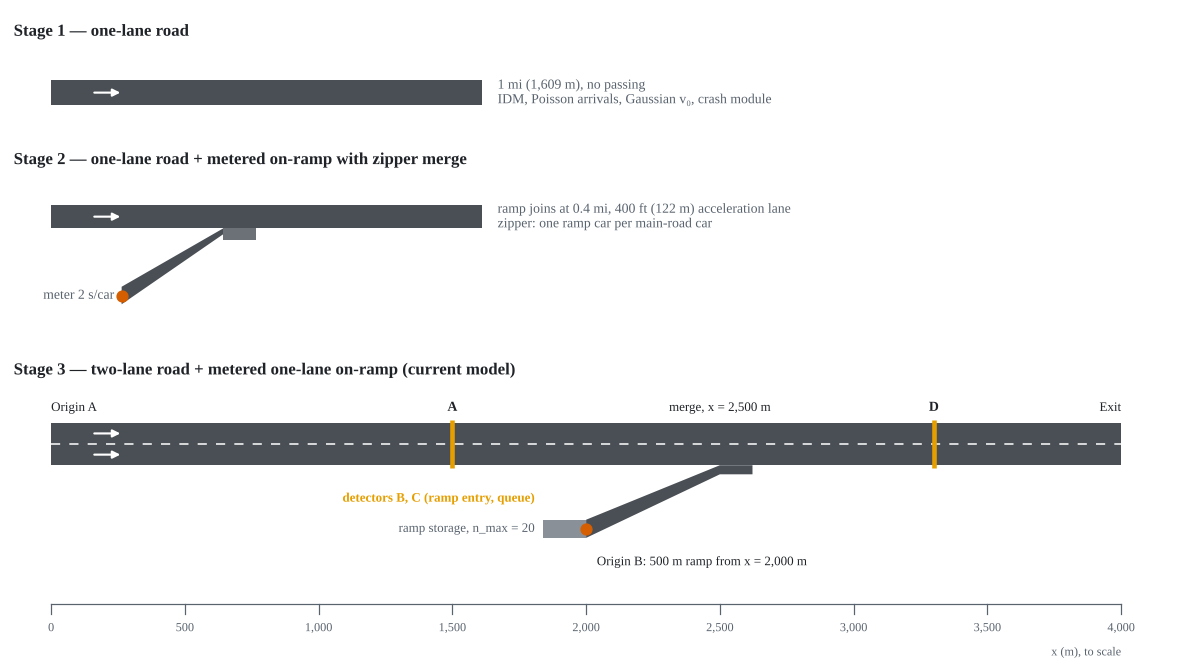

In [3]:
fig, axs = plt.subplots(3, 1, figsize=(11, 6.2), gridspec_kw=dict(height_ratios=[.7, 1.15, 1.9]))
ROAD = "#4a4f55"
def road(ax, x0, x1, y, h, lanes=1):
    ax.add_patch(Rectangle((x0, y), x1 - x0, h, color=ROAD, lw=0))
    for k in range(1, lanes): ax.plot([x0, x1], [y + h*k/lanes]*2, color="w", lw=1, ls=(0, (6, 6)))
def arrow(ax, x, y, txt=None):
    ax.annotate("", xy=(x + 120, y), xytext=(x, y), arrowprops=dict(arrowstyle="-|>", color="w", lw=1.4))
def det(ax, x, y0, y1, name):
    ax.plot([x, x], [y0, y1], color=C5, lw=3, solid_capstyle="butt"); ax.text(x, y1 + 2, name, ha="center", va="bottom", fontsize=9, color=INK, weight="bold")
for ax in axs: ax.set_axis_off(); ax.set_xlim(-150, 4250)

ax = axs[0]; L1 = 1609; ax.set_ylim(-6, 30)
road(ax, 0, L1, 0, 8); arrow(ax, 150, 4)
ax.text(-140, 22, "Stage 1 — one-lane road", fontsize=11, weight="bold", color=INK)
ax.text(L1 + 60, 4, "1 mi (1,609 m), no passing\nIDM, Poisson arrivals, Gaussian v₀, crash module", va="center", fontsize=9, color=MUTED)

ax = axs[1]; ax.set_ylim(-34, 30)
road(ax, 0, L1, 0, 8); arrow(ax, 150, 4)
M2 = 0.4 * 1609; E2 = M2 + 400 * FT
ax.add_patch(Polygon([[M2 - 380, -26], [M2, -2], [E2, -2], [E2, 0], [M2, 0], [M2 - 380, -20]], color=ROAD, lw=0))
ax.add_patch(Rectangle((M2, -4), E2 - M2, 4, color="#6b7177", lw=0))
ax.plot(M2 - 380, -23, "o", color=C2, ms=7); ax.text(M2 - 395, -23, "meter 2 s/car ", ha="right", va="center", fontsize=9, color=MUTED)
ax.text(-140, 22, "Stage 2 — one-lane road + metered on-ramp with zipper merge", fontsize=11, weight="bold", color=INK)
ax.text(L1 + 60, 4, "ramp joins at 0.4 mi, 400 ft (122 m) acceleration lane\nzipper: one ramp car per main-road car", va="center", fontsize=9, color=MUTED)

ax = axs[2]; ax.set_ylim(-62, 40)
road(ax, 0, 4000, 0, 14, lanes=2); arrow(ax, 150, 3.5); arrow(ax, 150, 10.5)
R0, M, E = 2000, 2500, 2500 + 400*FT
ax.add_patch(Polygon([[R0, -24], [M, -3], [E, -3], [E, 0], [M, 0], [R0, -18]], color=ROAD, lw=0))
ax.add_patch(Rectangle((R0 - 160, -24), 160, 6, color="#8a9097", lw=0)); ax.text(R0 - 180, -21, "ramp storage, n_max = 20 ", ha="right", va="center", fontsize=8.5, color=MUTED)
ax.plot(R0, -21, "o", color=C2, ms=7)
for x, n in ((1500, "A"), (3300, "D")): det(ax, x, -1, 15, n)
ax.text(R0 - 180, -11, "detectors B, C (ramp entry, queue) ", ha="right", va="center", fontsize=8.5, color=C5, weight="bold")
ax.text(-140, 30, "Stage 3 — two-lane road + metered one-lane on-ramp (current model)", fontsize=11, weight="bold", color=INK)
for x, lab, ha in ((0, "Origin A", "left"), (2500, "merge, x = 2,500 m", "center"), (4000, "Exit", "right")):
    ax.text(x, 17, lab, ha=ha, va="bottom", fontsize=8.5, color=INK)
ax.text(R0 + 40, -30, "Origin B: 500 m ramp from x = 2,000 m", ha="left", va="top", fontsize=8.5, color=INK)
for x in range(0, 4001, 500):
    ax.plot([x, x], [-46, -49], color=MUTED, lw=.8); ax.text(x, -52, f"{x:,}", ha="center", va="top", fontsize=8, color=MUTED)
ax.plot([0, 4000], [-46, -46], color=MUTED, lw=.8); ax.text(4000, -60, "x (m), to scale", ha="right", va="top", fontsize=8, color=MUTED)
fig.tight_layout(); save(fig, "fig01_three_stages"); plt.show()

## Fig 0 — System layout and dimensions, to scale

saved reports/midterm/figures/fig00_system_layout.png


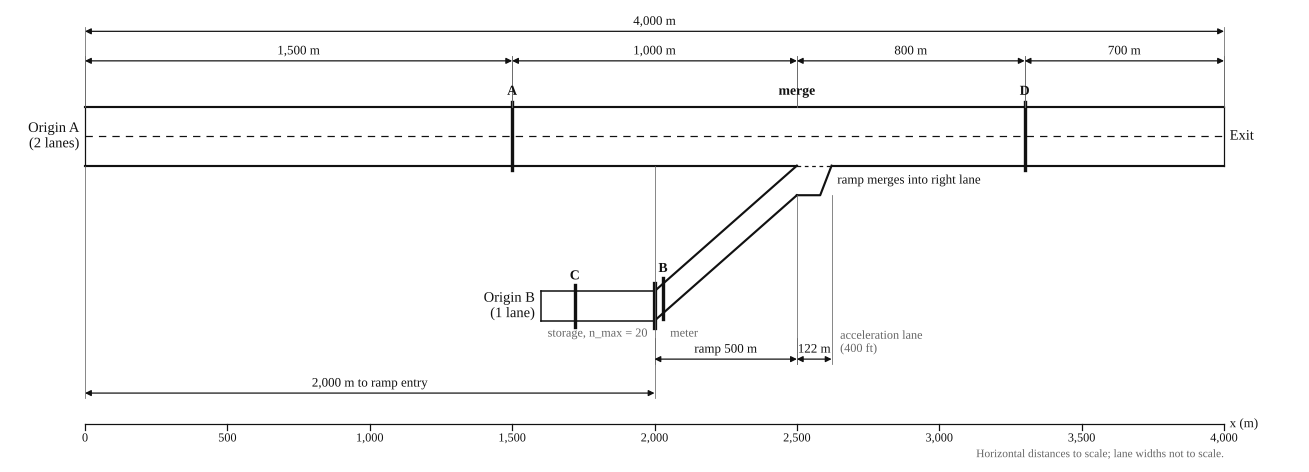

In [4]:
K, G = "#111111", "#666666"

L_, XR, XM = 4000, 2000, 2500
XE = XM + 400 * FT            # end of acceleration lane, 2,621.9 m
XA, XD = 1500, 3300
W = 40                        # drawn lane width (exaggerated)
fig, ax = plt.subplots(figsize=(12, 4.4))
ax.set_xlim(-260, 4260); ax.set_ylim(-400, 210); ax.set_axis_off()

# main road: outer edges, lane divider
ax.plot([0, L_], [2 * W, 2 * W], color=K, lw=1.4)                 # left edge
ax.plot([0, XM], [0, 0], color=K, lw=1.4)                         # right edge up to merge
ax.plot([XE, L_], [0, 0], color=K, lw=1.4)                         # right edge after accel. lane
ax.plot([0, L_], [W, W], color=K, lw=0.8, ls=(0, (6, 5)))          # lane divider
ax.plot([0, 0], [0, 2 * W], color=K, lw=0.8); ax.plot([L_, L_], [0, 2 * W], color=K, lw=0.8)
# acceleration lane (122 m) below the right lane, tapering into it at its end
ax.plot([XM, XE - 40, XE], [-W, -W, 0], color=K, lw=1.4)
ax.plot([XM, XE], [0, 0], color=K, lw=0.8, ls=(0, (3, 3)))
# ramp: one lane, 500 m, from the meter at x = 2,000 m to the merge at x = 2,500 m
yr = -170
ax.plot([XR, XM], [yr, 0], color=K, lw=1.4)          # upper edge meets the road edge at the merge
ax.plot([XR, XM], [yr - W, -W], color=K, lw=1.4)     # lower edge continues as the acceleration lane
# ramp storage (n_max = 20) behind the meter
sx0 = XR - 400
ax.plot([sx0, XR], [yr, yr], color=K, lw=1.0); ax.plot([sx0, XR], [yr - W, yr - W], color=K, lw=1.0)
ax.plot([sx0, sx0], [yr, yr - W], color=K, lw=1.0)
ax.text((sx0 + XR) / 2, yr - W - 10, "storage, n_max = 20", ha="center", va="top", fontsize=8, color=G)
ax.plot([XR, XR], [yr + 10, yr - W - 10], color=K, lw=2.8)   # meter stop line
ax.text(XR + 55, yr - W - 10, "meter", ha="left", va="top", fontsize=8, color=G)

# detectors: short bars across the lanes + labels
def det(x, y0, y1, lab, ytxt, ha="center"):
    ax.plot([x, x], [y0, y1], color=K, lw=2.2)
    ax.text(x, ytxt, lab, ha=ha, va="bottom", fontsize=9, color=K, weight="bold")
det(XA, -6, 2 * W + 6, "A", 2 * W + 12); det(XD, -6, 2 * W + 6, "D", 2 * W + 12)
det(XR + 30, yr + 8 + 10, yr - W + 2, "B", yr + 22)          # ramp entry, just past the meter
det(sx0 + 120, yr + 8, yr - W - 8, "C", yr + 12)         # ramp queue

# end labels
ax.text(-20, W, "Origin A\n(2 lanes)", ha="right", va="center", fontsize=9.5, color=K)
ax.text(L_ + 20, W, "Exit", ha="left", va="center", fontsize=9.5, color=K)
ax.text(sx0 - 20, yr - W * 0.5, "Origin B\n(1 lane)", ha="right", va="center", fontsize=9.5, color=K)
ax.text(XE + 20, -W / 2, "ramp merges into right lane", ha="left", va="center", fontsize=8.5, color=K)
ax.text(XM, 2 * W + 12, "merge", ha="center", va="bottom", fontsize=9, color=K, weight="bold")

# dimension lines
def dim(x0, x1, y, text, ext_from=None):
    ax.annotate("", xy=(x0, y), xytext=(x1, y), arrowprops=dict(arrowstyle="<|-|>", color=K, lw=0.8, shrinkA=0, shrinkB=0, mutation_scale=8))
    ax.text((x0 + x1) / 2, y + 5, text, ha="center", va="bottom", fontsize=8.5, color=K)
    if ext_from is not None:
        for x in (x0, x1):
            ax.plot([x, x], [ext_from, y + (6 if y > ext_from else -6)], color=G, lw=0.5)
ytop = 2 * W + 62
dim(0, L_, ytop + 40, "4,000 m", ext_from=2 * W)
dim(0, XA, ytop, "1,500 m", ext_from=2 * W); dim(XA, XM, ytop, "1,000 m", ext_from=2 * W)
dim(XM, XD, ytop, "800 m", ext_from=2 * W); dim(XD, L_, ytop, "700 m", ext_from=2 * W)
ybot = -262
dim(XR, XM, ybot, "ramp 500 m", ext_from=yr - W - 24)
dim(XM, XE, ybot, "122 m", ext_from=-W)
ax.text(XE + 30, ybot + 5, "acceleration lane\n(400 ft)", ha="left", va="bottom", fontsize=8, color=G)
dim(0, XR, ybot - 46, "2,000 m to ramp entry", ext_from=0)

# position axis
ya = -350
ax.plot([0, L_], [ya, ya], color=K, lw=0.8)
for x in range(0, L_ + 1, 500):
    ax.plot([x, x], [ya, ya - 8], color=K, lw=0.8)
    ax.text(x, ya - 12, f"{x:,}", ha="center", va="top", fontsize=8, color=K)
ax.text(L_ + 20, ya, "x (m)", ha="left", va="center", fontsize=8.5, color=K)
ax.text(L_, ya - 34, "Horizontal distances to scale; lane widths not to scale.", ha="right", va="top", fontsize=7.5, color=G)
fig.tight_layout()
save(fig, "fig00_system_layout"); plt.show()

## Fig 2 — IDM car-following model

saved reports/midterm/figures/fig02_idm_model.png


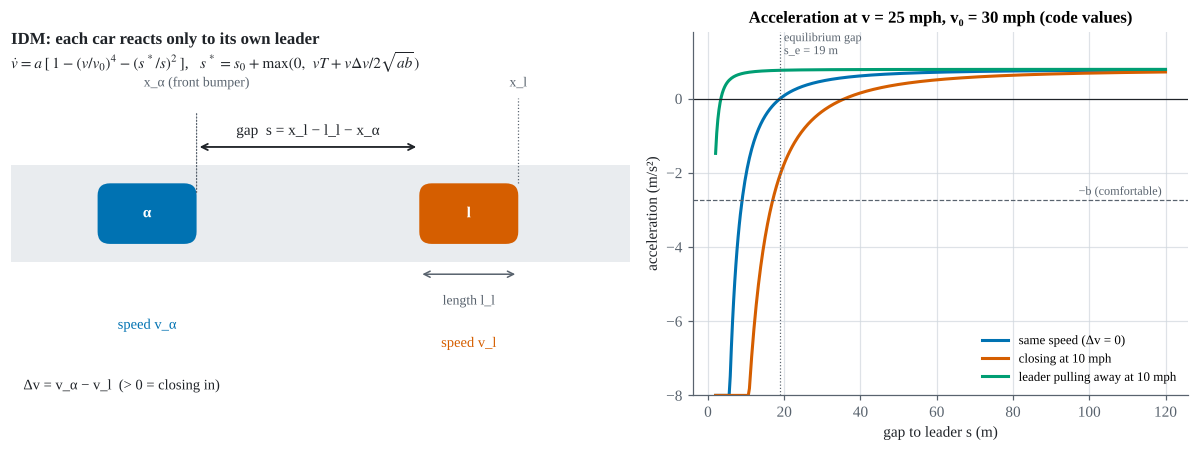

In [5]:
fig = plt.figure(figsize=(11, 4.2)); gs = fig.add_gridspec(1, 2, width_ratios=[1.25, 1])
ax = fig.add_subplot(gs[0]); ax.set_axis_off(); ax.set_xlim(0, 100); ax.set_ylim(0, 60)
ax.add_patch(Rectangle((0, 22), 100, 16, color="#e9ecef", lw=0))
def car(x, col, lab):
    ax.add_patch(FancyBboxPatch((x, 25), 16, 10, boxstyle="round,pad=0,rounding_size=2", color=col, lw=0))
    ax.text(x + 8, 30, lab, ha="center", va="center", color="w", fontsize=10, weight="bold")
car(14, C1, "α"); car(66, C2, "l")
ax.annotate("", xy=(30, 33), xytext=(30, 47), arrowprops=dict(arrowstyle="-", color=MUTED, lw=.8, ls=":"))
ax.annotate("", xy=(66, 41), xytext=(30, 41), arrowprops=dict(arrowstyle="<->", color=INK, lw=1.2))
ax.text(48, 43, "gap  s = x_l − l_l − x_α", ha="center", fontsize=10, color=INK)
ax.annotate("", xy=(82, 20), xytext=(66, 20), arrowprops=dict(arrowstyle="<->", color=MUTED, lw=1)); ax.text(74, 15, "length l_l", ha="center", fontsize=9, color=MUTED)
ax.text(30, 51, "x_α (front bumper)", ha="center", fontsize=9, color=MUTED); ax.text(82, 51, "x_l", ha="center", fontsize=9, color=MUTED)
ax.plot([82, 82], [35, 49], color=MUTED, lw=.8, ls=":")
ax.text(22, 11, "speed v_α", ha="center", fontsize=9.5, color=C1); ax.text(74, 8, "speed v_l", ha="center", fontsize=9.5, color=C2)
ax.text(2, 1, "Δv = v_α − v_l  (> 0 = closing in)", fontsize=9.5, color=INK)
ax.text(0, 58, "IDM: each car reacts only to its own leader", fontsize=11, weight="bold", color=INK)
ax.text(0, 54, r"$\dot v = a\,[\,1-(v/v_0)^4-(s^*/s)^2\,]$,   $s^* = s_0+\max(0,\;vT+v\Delta v/2\sqrt{ab})$", fontsize=10, color=INK)

ax = fig.add_subplot(gs[1])
s = np.linspace(2, 120, 400); v = 25*MPH; v0 = 30*MPH
for dv_mph, col, lab in ((0, C1, "same speed (Δv = 0)"), (10, C2, "closing at 10 mph"), (-10, C3, "leader pulling away at 10 mph")):
    a_ = th.idm_acc(v/FT, v0/FT, s/FT, dv_mph*MPH/FT, a=5, b=9, T=1.0, s0=8) * FT
    ax.plot(s, np.clip(a_, -8, None), color=col, lw=2, label=lab)
ax.axhline(0, color=INK, lw=.8); ax.axhline(-9*FT, color=MUTED, lw=.8, ls="--"); ax.text(119, -9*FT + .15, "−b (comfortable)", ha="right", fontsize=8, color=MUTED)
se = (8*FT + v*1.0) / np.sqrt(1 - (v/v0)**4); ax.axvline(se, color=MUTED, lw=.8, ls=":"); ax.text(se + 1, 1.2, f"equilibrium gap\ns_e = {se:.0f} m", fontsize=8, color=MUTED)
ax.set(xlabel="gap to leader s (m)", ylabel="acceleration (m/s²)", ylim=(-8, 1.8), title="Acceleration at v = 25 mph, v₀ = 30 mph (code values)")
ax.legend(loc="lower right")
fig.tight_layout(); save(fig, "fig02_idm_model"); plt.show()

## Run all experiments

In [6]:
def P(**kw): return dict(crash=0, **kw)
EXP = {}
EXP["mdl"] = [dict(params=P(flow=800, ramp=lam, meter=3600/mu), duration_s=7200, seed=s) for lam, mu in ((400, 900), (600, 900), (600, 720)) for s in SEEDS]
EXP["cong"] = [dict(params=P(flow=2800, ramp=700, meter=4.5), duration_s=3600, seed=s, record_traj=(s == 1), traj_every_s=4, traj_from_s=600) for s in SEEDS]
EXP["h1"] = [dict(params=P(flow=2400, ramp=q, meter=2.0, headway=1.0), duration_s=3600, seed=s) for q in (300, 450, 600, 750, 900, 1200) for s in SEEDS]
EXP["h2"] = [dict(params=P(flow=2400, ramp=q, meter=2.0, headway=1.5), duration_s=3600, seed=s) for q in (0, 150, 300, 450, 600, 900) for s in SEEDS]
EXP["h5"] = [dict(params=P(flow=3600, ramp=600, meter=2.0, mean=v), duration_s=3600, seed=s) for v in (35, 55, 75) for s in SEEDS]
EXP["inc"] = [dict(params=dict(flow=2400, ramp=300, crash=0, clear=0.25), duration_s=3600, seed=s, crash_at=ca)
              for s in SEEDS for ca in (dict(t_s=1200, x_m=2000, lane=0), None)]
LECTURE_CONSTS = dict(IA=1.0/FT, IB=1.5/FT, S0=2.0/FT, CL=5.0/FT)
pulse = dict(t_s=900, x_m=1800, decel_mps2=3, dur_s=3, lane=0, n_followers=12, window_s=150)
EXP["h3"] = [dict(params=P(flow=f, ramp=0, lc=False), consts=c, duration_s=1080, seed=s, pulse=dict(pulse, apply=ap))
             for c in ({}, LECTURE_CONSTS) for f in (1200, 2400, 3200) for s in SEEDS for ap in (True, False)]
R = {}
for k, cfg in EXP.items():
    t = time.time(); R[k] = st.run_many(cfg); print(f"{k:5s} {len(cfg):3d} runs  {time.time()-t:5.1f} s")
bad = [(k, o) for k, v in R.items() for o in v if o["checks"]["negative_gap_events"] or o["checks"]["main_balance"] or o["checks"]["ramp_balance"]]
print("QA/QC failures:", "none" if not bad else "")
for k, o in bad:
    c = o["checks"]; e = c["negative_gap_log"][0] if c["negative_gap_log"] else {}
    print(f"  {k}, seed {o['seed']}, params {dict((x, o['params'][x]) for x in ('flow','ramp','mean','headway'))}: {c['negative_gap_events']} overlap steps, "
          f"min gap {c['min_gap_ft']*FT:.2f} m at x = {e.get('x_m')} m, t = {e.get('t_s')} s (follower {e.get('v_follower_mph')} mph, leader {e.get('v_leader_mph')} mph, "
          f"same leader for {e.get('same_leader_for_s')} s) — conservation {c['main_balance']}/{c['ramp_balance']}")

mdl     9 runs   19.6 s


cong    3 runs   18.6 s


h1     18 runs   60.4 s


h2     18 runs   66.5 s


h5      9 runs   39.3 s


inc     6 runs   18.8 s


h3     36 runs   18.0 s
QA/QC failures: 
  h5, seed 2, params {'flow': 3600, 'ramp': 600, 'mean': 75, 'headway': 1}: 24 overlap steps, min gap -3.75 m at x = 2570.5 m, t = 181.7 s (follower 21.5 mph, leader 4.7 mph, same leader for 99.1 s) — conservation 0/0


## Fig 14 — Verification: ramp queue vs. M/D/1

,lam,mu,rho,L_theory,Lq_theory,L_sim,seed,err_pct
0,400,900,0.444,0.622,0.178,0.624,2.0,0.224
1,600,900,0.667,1.333,0.667,1.408,2.0,5.627
2,600,720,0.833,2.917,2.083,3.436,2.0,17.802


saved reports/midterm/figures/fig14_ramp_queue_md1.png


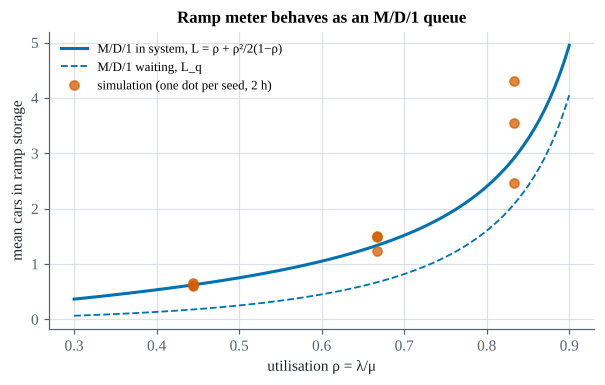

In [7]:
rows = []
for o in R["mdl"]:
    c = warm(st.detectors_df(o)); c = c[c.sensor == "C"]
    lam, mu = o["params"]["ramp"], 3600 / o["params"]["meter"]; m = th.md1(lam, mu)
    rows.append(dict(lam=lam, mu=round(mu), rho=m["rho"], L_theory=m["L"], Lq_theory=m["Lq"], L_sim=c.avg_queue.mean(), seed=o["seed"]))
f3 = pd.DataFrame(rows); g3 = f3.groupby(["lam", "mu"], sort=False).mean().reset_index(); g3["err_pct"] = 100*(g3.L_sim/g3.L_theory - 1)
display(g3.round(3)); g3.to_csv(TAB / "fig14_md1.csv", index=False)
fig, ax = plt.subplots(figsize=(5.6, 3.6))
r = np.linspace(.3, .9, 100); ax.plot(r, r + r**2/(2*(1-r)), color=C1, lw=2, label="M/D/1 in system, L = ρ + ρ²/2(1−ρ)")
ax.plot(r, r**2/(2*(1-r)), color=C1, lw=1.2, ls="--", label="M/D/1 waiting, L_q")
ax.plot(f3.rho, f3.L_sim, "o", color=C2, alpha=.75, label="simulation (one dot per seed, 2 h)")
ax.set(xlabel="utilisation ρ = λ/μ", ylabel="mean cars in ramp storage", title="Ramp meter behaves as an M/D/1 queue"); ax.legend()
fig.tight_layout(); save(fig, "fig14_ramp_queue_md1"); plt.show()

## Fig 15 — The merge as the bottleneck

saved reports/midterm/figures/fig15_merge_bottleneck.png


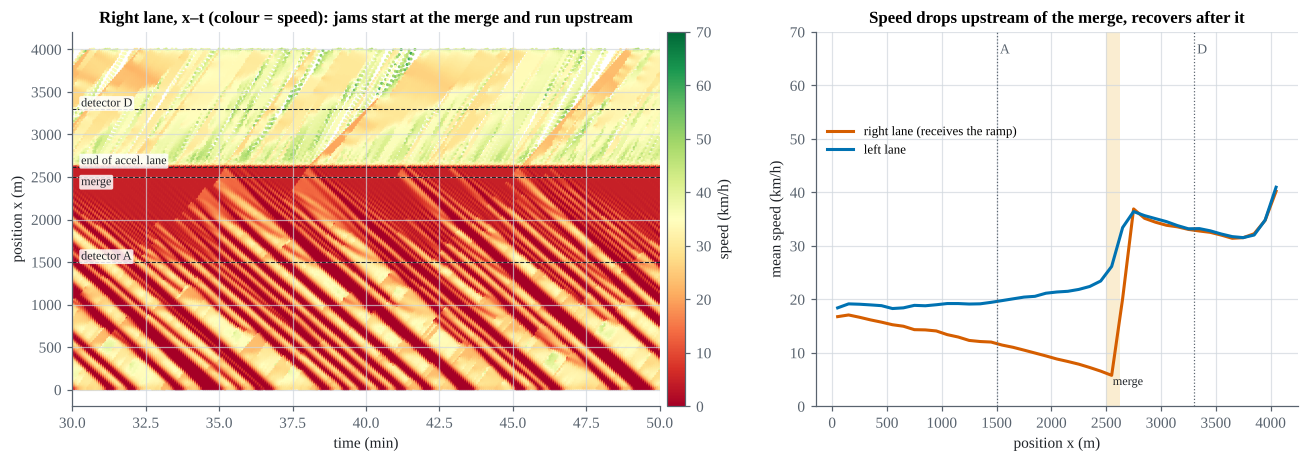

In [8]:
o = R["cong"][0]; tj = st.traj_df(o)
fig, axs = plt.subplots(1, 2, figsize=(12, 4.3), gridspec_kw=dict(width_ratios=[1.45, 1]))
ax = axs[0]; tr = tj[(tj.lane == 0) & (tj.t_s >= 1800) & (tj.t_s <= 3000)]
sc = ax.scatter(tr.t_s/60, tr.x_m, c=tr.v_kmh, s=1.0, cmap="RdYlGn", vmin=0, vmax=70, rasterized=True)
for x, n in ((1500, "detector A"), (2500, "merge"), (2500 + 400*FT, "end of accel. lane"), (3300, "detector D")):
    ax.axhline(x, color=INK, lw=.7, ls="--")
for x, n, dy in ((1500, "detector A", 30), (2500, "merge", -95), (2500 + 400*FT, "end of accel. lane", 30), (3300, "detector D", 30)):
    ax.text(30.3, x + dy, n, fontsize=8, color=INK, ha="left", bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=.85))
ax.set(xlabel="time (min)", ylabel="position x (m)", title="Right lane, x–t (colour = speed): jams start at the merge and run upstream", xlim=(30, 50))
cb = plt.colorbar(sc, ax=ax, pad=.01); cb.set_label("speed (km/h)")
ax = axs[1]; w = tj[tj.t_s >= 600].copy(); w["xb"] = (w.x_m // 100) * 100 + 50
for ln, col, lab in ((0, C2, "right lane (receives the ramp)"), (1, C1, "left lane")):
    g = w[w.lane == ln].groupby("xb").v_kmh.mean(); ax.plot(g.index, g.values, color=col, lw=2, label=lab)
ax.axvspan(2500, 2500 + 400*FT, color=C5, alpha=.18, lw=0); ax.text(2560, 4, "merge", fontsize=8, color=INK)
for x, n in ((1500, "A"), (3300, "D")): ax.axvline(x, color=MUTED, lw=.8, ls=":"); ax.text(x + 30, 66, n, fontsize=9, color=MUTED)
ax.set(xlabel="position x (m)", ylabel="mean speed (km/h)", ylim=(0, 70), title="Speed drops upstream of the merge, recovers after it"); ax.legend(loc="upper left", bbox_to_anchor=(0.0, 0.78))
fig.tight_layout(); save(fig, "fig15_merge_bottleneck"); plt.show()

## Fig 16 — Fundamental diagram from detector data

saved reports/midterm/figures/fig16_fundamental_diagram.png


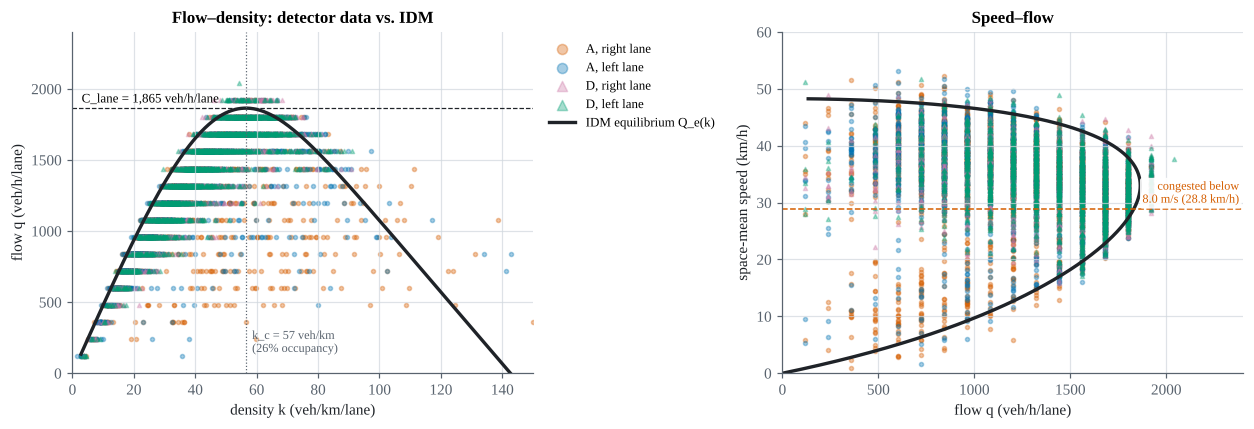

8,395 detector intervals from 21 runs


In [9]:
dets = pd.concat([warm(st.detectors_df(o)).assign(qB=o["params"]["ramp"]) for o in R["h1"] + R["cong"]])
dets = dets[dets.sensor.isin(["A", "D"]) & dets.smean_kmh.notna()]
_, k_eq, q_eq = th.idm_equilibrium(30*MPH, 1.0, 8*FT, 15*FT); v_eq = q_eq / np.maximum(k_eq, 1e-9)
kc = k_eq[np.argmax(q_eq)]
fig, axs = plt.subplots(1, 2, figsize=(11.5, 4))
for (sen, ln), col, mk in ((("A", "R"), C2, "o"), (("A", "L"), C1, "o"), (("D", "R"), C4, "^"), (("D", "L"), C3, "^")):
    g = dets[(dets.sensor == sen) & (dets.lane == ln)]
    lab = f"{sen}, {'right' if ln == 'R' else 'left'} lane"
    axs[0].scatter(g.density_vpkm, g.flow_vph, s=7, alpha=.35, color=col, marker=mk, label=lab, rasterized=True)
    axs[1].scatter(g.flow_vph, g.smean_kmh, s=7, alpha=.35, color=col, marker=mk, label=lab, rasterized=True)
axs[0].plot(k_eq, q_eq, color=INK, lw=2.2, label="IDM equilibrium Q_e(k)"); axs[0].axhline(CAP_CODE, color=INK, lw=.8, ls="--")
axs[0].text(3, CAP_CODE + 40, f"C_lane = {CAP_CODE:,.0f} veh/h/lane", ha="left", fontsize=8.5)
axs[0].axvline(kc, color=MUTED, lw=.8, ls=":"); axs[0].text(kc + 2, 150, f"k_c = {kc:.0f} veh/km\n(26% occupancy)", fontsize=8, color=MUTED)
axs[0].set(xlabel="density k (veh/km/lane)", ylabel="flow q (veh/h/lane)", xlim=(0, 150), ylim=(0, 2400), title="Flow–density: detector data vs. IDM")
axs[1].plot(q_eq, v_eq, color=INK, lw=2.2, label="IDM equilibrium"); axs[1].axhline(8.0*3.6, color=C2, lw=1, ls="--")
axs[1].text(2380, 8.0*3.6 + 1.2, "congested below\n8.0 m/s (28.8 km/h)", fontsize=8, color=C2, ha="right", bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="none", alpha=.9))
axs[1].set(xlabel="flow q (veh/h/lane)", ylabel="space-mean speed (km/h)", xlim=(0, 2400), ylim=(0, 60), title="Speed–flow")
axs[0].legend(loc="upper left", markerscale=2.5, bbox_to_anchor=(1.01, 1))
fig.tight_layout(); save(fig, "fig16_fundamental_diagram"); plt.show()
print(f"{len(dets):,} detector intervals from {len(R['h1']) + len(R['cong'])} runs")

## Fig 3 — H1 and H2: merge capacity threshold

flow_D_vph       unserved_pct      trip_speed_mph      ramp_wait_s  \
               mean   std         mean  std           mean  std        mean   
T   qB                                                                        
1.0 300      2686.0  45.5          0.5  1.7           21.3  0.4        57.7   
    450      2815.6  89.6          1.2  3.1           20.7  0.6        71.6   
    600      2854.4  35.4          4.9  1.2           19.1  0.8        96.7   
    750      2912.4   7.9          7.5  0.2           17.0  0.9       311.9   
    900      2904.0  23.1         12.0  0.7           16.9  0.6       376.3   
    1200     2910.0  44.4         19.2  1.2           16.1  0.8       435.0   
1.5 0        2396.4  84.2          0.2  3.5           18.1  0.6         NaN   
    150      2501.2  71.1          1.9  2.8           18.3  1.0        56.6   
    300      2608.0  30.6          3.4  1.1           17.8  0.7        63.7   
    450      2567.2  13.8          9.9  0.5           15.1  1.6        73.7   
    600      2498.4   9.8         16.7  0.3           13.1  0.9       186.8   
    900      2503.2   9.1         24.1  0.3           12.4  0.3       418.3   

               breakdowns       
           std       mean  std  
T   qB                          
1.0 300    1.0        0.7  0.6  
    450    8.2        1.0  1.0  
    600   22.9        1.0  1.0  
    750   49.1        2.0  1.0  
    900   39.7        2.3  1.2  
    1200   7.5        2.3  0.6  
1.5 0      NaN        4.0  1.0  
    150    2.1        3.3  2.1  
    300    1.5        4.3  2.1  
    450    5.4        3.0  1.7  
    600   66.4        2.3  0.6  
    900   18.4        1.7  0.6

saved reports/midterm/figures/fig03_h1_h2_threshold.png


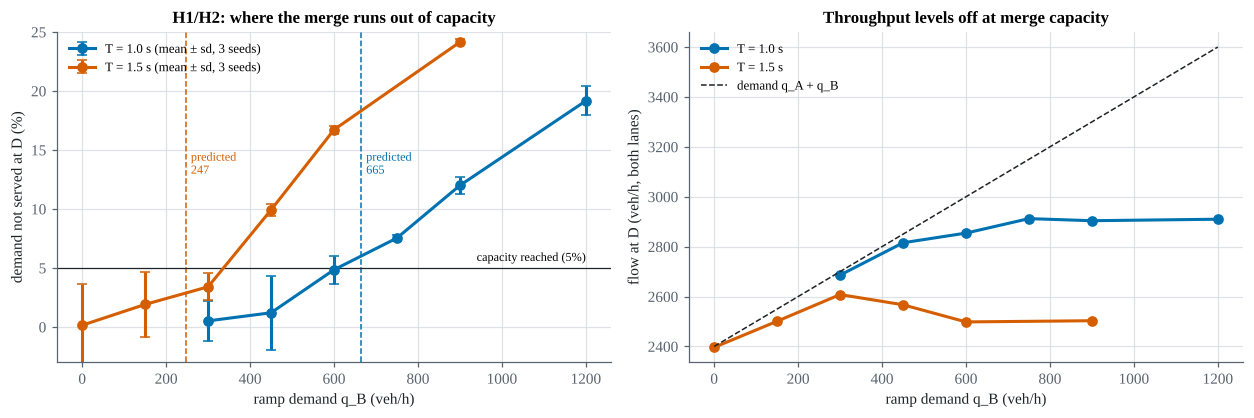

T = 1.0: >5% unserved first at q_B = 750; predicted 665
T = 1.5: >5% unserved first at q_B = 450; predicted 247


In [10]:
def sweep_table(outs, qA=2400):
    rows = []
    for o in outs:
        r = st.summary_row(o, qB=o["params"]["ramp"], T=o["params"]["headway"]); r["unserved_pct"] = 100*(1 - r["flow_D_vph"]/(qA + r["qB"]))
        rows.append(r)
    return pd.DataFrame(rows)
f6 = pd.concat([sweep_table(R["h1"]), sweep_table(R["h2"])])
g6 = f6.groupby(["T", "qB"])[["flow_D_vph", "unserved_pct", "trip_speed_mph", "ramp_wait_s", "breakdowns"]].agg(["mean", "std"])
display(g6.round(1)); f6.to_csv(TAB / "fig03_h1_h2_sweeps.csv", index=False)
cap15 = th.idm_capacity(30*MPH, 1.5, 8*FT, 15*FT)[0]
pred = {1.0: CAP_CODE - 1200, 1.5: cap15 - 1200}
fig, axs = plt.subplots(1, 2, figsize=(11.5, 3.9))
for T, col in ((1.0, C1), (1.5, C2)):
    g = f6[f6["T"] == T].groupby("qB"); m, sd = g.unserved_pct.mean(), g.unserved_pct.std()
    axs[0].errorbar(m.index, m.values, yerr=sd.values, color=col, marker="o", capsize=3, lw=2, label=f"T = {T} s (mean ± sd, 3 seeds)")
    axs[0].axvline(pred[T], color=col, lw=1, ls="--"); axs[0].text(pred[T] + 12, 13, f"predicted\n{pred[T]:.0f}", color=col, fontsize=8)
    gD = g.flow_D_vph.mean(); axs[1].plot(gD.index, gD.values, color=col, marker="o", lw=2, label=f"T = {T} s")
axs[0].axhline(5, color=INK, lw=.8); axs[0].text(1200, 5.6, "capacity reached (5%)", ha="right", fontsize=8)
axs[0].set(xlabel="ramp demand q_B (veh/h)", ylabel="demand not served at D (%)", title="H1/H2: where the merge runs out of capacity", ylim=(-3, 25)); axs[0].legend(loc="upper left")
q = np.array([0, 1200]); axs[1].plot(q, 2400 + q, color=INK, lw=1, ls="--", label="demand q_A + q_B")
axs[1].set(xlabel="ramp demand q_B (veh/h)", ylabel="flow at D (veh/h, both lanes)", title="Throughput levels off at merge capacity"); axs[1].legend(loc="upper left")
fig.tight_layout(); save(fig, "fig03_h1_h2_threshold"); plt.show()
for T in (1.0, 1.5):
    m = f6[f6["T"] == T].groupby("qB").unserved_pct.mean(); over = m[m > 5]
    print(f"T = {T}: >5% unserved first at q_B = {over.index[0] if len(over) else 'never'}; predicted {pred[T]:.0f}")

## Fig 7 — H3: wave speed and string stability

mean   min   max
params            flow                  
Lecture 04 values 1200  0.05  0.00  0.12
                  2400  0.88  0.84  0.92
                  3200  0.88  0.87  0.90
code values       1200  0.75  0.59  0.85
                  2400  0.70  0.53  0.93
                  3200  0.84  0.76  0.89

saved reports/midterm/figures/fig07_h3_waves_stability.png


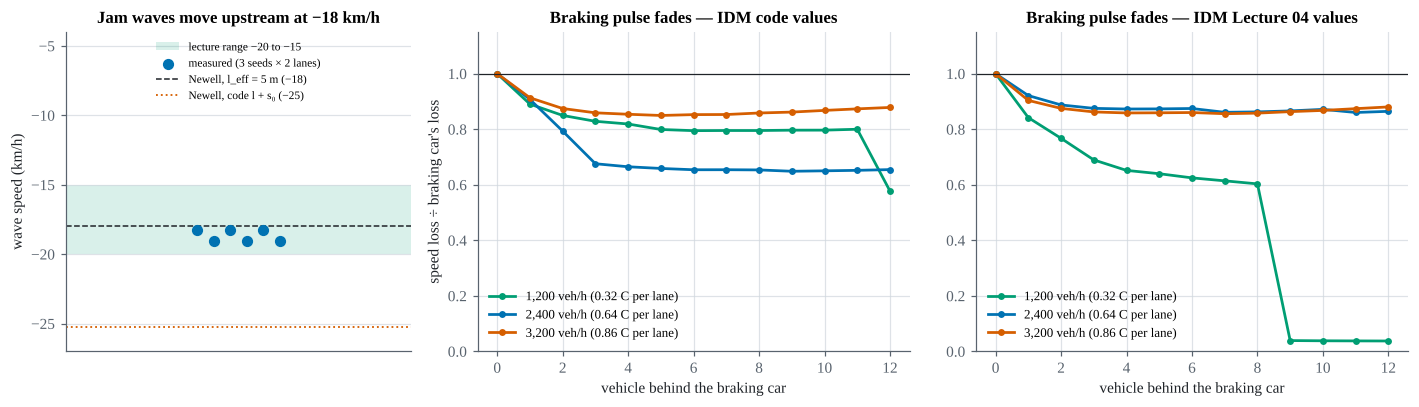

wave speeds (km/h): [-18.3 -19.1 -18.3 -19.1 -18.3 -19.1]


In [11]:
w = [o["wave_xcorr_mph"][ln] for o in R["cong"] for ln in ("right", "left") if o["wave_xcorr_mph"][ln] is not None]
w_kmh = np.array(w) * KMH
rows, curves = [], {}
h3 = R["h3"]
for i in range(0, len(h3), 2):
    a, b = h3[i], h3[i+1]; name = "Lecture 04 values" if a["input"]["consts"] else "code values"
    loss = np.nanmax(np.array(b["pulse"]["v_mph"], float) - np.array(a["pulse"]["v_mph"], float), axis=0)
    rows.append(dict(params=name, flow=a["params"]["flow"], seed=a["seed"], ratio=loss[10]/loss[0])); curves.setdefault((name, a["params"]["flow"]), []).append(loss/loss[0])
f7 = pd.DataFrame(rows); display(f7.groupby(["params", "flow"]).ratio.describe()[["mean", "min", "max"]].round(2)); f7.to_csv(TAB / "fig07_pulse.csv", index=False)
fig, axs = plt.subplots(1, 3, figsize=(13, 3.8), gridspec_kw=dict(width_ratios=[.8, 1, 1]))
ax = axs[0]; ax.axhspan(-20, -15, color=C3, alpha=.15, lw=0, label="lecture range −20 to −15")
ax.scatter(np.zeros(len(w_kmh)) + np.linspace(-.12, .12, len(w_kmh)), w_kmh, color=C1, s=40, zorder=3, label="measured (3 seeds × 2 lanes)")
ax.axhline(th.newell_wave_speed_kmh(5.0, 1.0), color=INK, ls="--", lw=1, label="Newell, l_eff = 5 m (−18)")
ax.axhline(th.newell_wave_speed_kmh(15*FT + 8*FT, 1.0), color=C2, ls=":", lw=1.2, label="Newell, code l + s₀ (−25)")
ax.set(xlim=(-.5, .5), ylim=(-27, -4), xticks=[], ylabel="wave speed (km/h)", title="Jam waves move upstream at −18 km/h"); ax.legend(loc="upper center", fontsize=7.5)
for j, name in enumerate(("code values", "Lecture 04 values")):
    ax = axs[j+1]
    for f, col in ((1200, C3), (2400, C1), (3200, C2)):
        c = np.median(curves[(name, f)], axis=0); ax.plot(range(len(c)), c, marker="o", ms=3.5, color=col, lw=1.8, label=f"{f:,} veh/h ({f/2/CAP_CODE:.2f} C per lane)")
    ax.axhline(1, color=INK, lw=.8); ax.set(xlabel="vehicle behind the braking car", ylim=(0, 1.15), title=f"Braking pulse fades — IDM {name}")
    ax.set_ylabel("speed loss ÷ braking car's loss" if j == 0 else ""); ax.legend(loc="lower left")
fig.tight_layout(); save(fig, "fig07_h3_waves_stability"); plt.show()
print("wave speeds (km/h):", np.round(w_kmh, 1))

## Fig 9 — H5: speed limit, throughput and crash risk

,cap_theory,flow_D_vph,capacity_gain_pct,throughput_gain_pct,trip_speed_mph,injury_x_posted,fatal_x_posted,injury_x_measured,fatal_x_measured
v,,,,,,,,,
35,3965.79,3126.8,0.00,0.00,14.84,1.00,1.00,1.00,1.00
55,4626.81,3366.0,16.67,7.65,20.67,2.47,6.10,1.94,3.76
75,5038.27,3476.4,27.04,11.18,22.88,4.59,21.08,2.38,5.65


saved reports/midterm/figures/fig09_h5_speed_limit.png


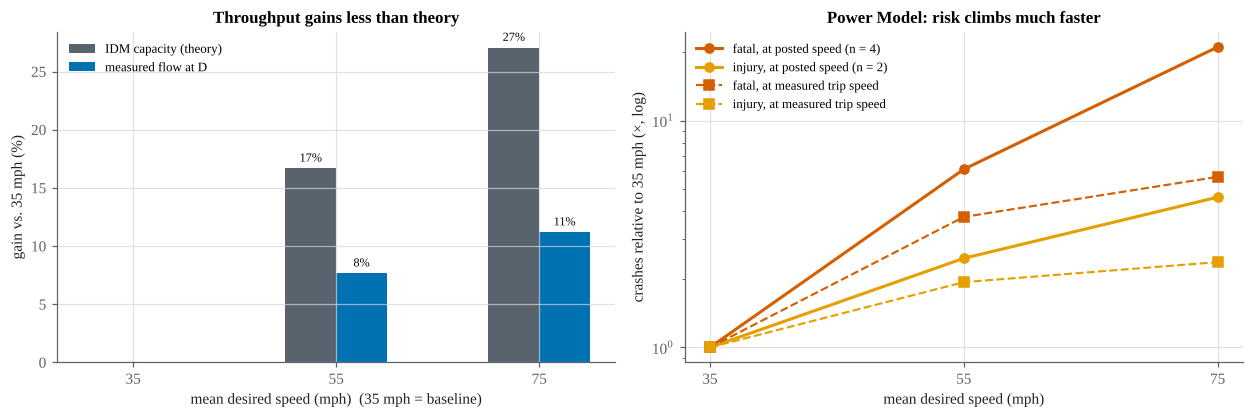

In [12]:
rows = []
for o in R["h5"]:
    r = st.summary_row(o, v=o["params"]["mean"]); d = warm(st.detectors_df(o)); a = d[d.sensor == "A"]
    r.update(speed_A_mph=(a["count"]*a.smean_mph).sum()/a["count"].sum(), cap_theory=2*th.idm_capacity(o["params"]["mean"]*MPH, 1.0, 8*FT, 15*FT)[0])
    rows.append(r)
f9 = pd.DataFrame(rows); g9 = f9.groupby("v").mean(numeric_only=True)
base = g9.loc[35]
g9["throughput_gain_pct"] = 100*(g9.flow_D_vph/base.flow_D_vph - 1); g9["capacity_gain_pct"] = 100*(g9.cap_theory/base.cap_theory - 1)
g9["injury_x_posted"] = (g9.index/35)**2; g9["fatal_x_posted"] = (g9.index/35)**4
g9["injury_x_measured"] = (g9.trip_speed_mph/base.trip_speed_mph)**2; g9["fatal_x_measured"] = (g9.trip_speed_mph/base.trip_speed_mph)**4
display(g9[["cap_theory", "flow_D_vph", "capacity_gain_pct", "throughput_gain_pct", "trip_speed_mph", "injury_x_posted", "fatal_x_posted", "injury_x_measured", "fatal_x_measured"]].round(2))
f9.to_csv(TAB / "fig09_h5_speed.csv", index=False)
fig, axs = plt.subplots(1, 2, figsize=(11.5, 3.9)); x = np.array(g9.index); wbar = 5
axs[0].bar(x - wbar/2, g9.capacity_gain_pct, width=wbar, color=MUTED, label="IDM capacity (theory)")
axs[0].bar(x + wbar/2, g9.throughput_gain_pct, width=wbar, color=C1, label="measured flow at D")
for xi, a_, b_ in zip(x[1:], g9.capacity_gain_pct[1:], g9.throughput_gain_pct[1:]):
    axs[0].text(xi - wbar/2, a_ + .6, f"{a_:.0f}%", ha="center", fontsize=8); axs[0].text(xi + wbar/2, b_ + .6, f"{b_:.0f}%", ha="center", fontsize=8)
axs[0].set(xticks=x, xlabel="mean desired speed (mph)  (35 mph = baseline)", ylabel="gain vs. 35 mph (%)", title="Throughput gains less than theory"); axs[0].legend(loc="upper left")
axs[1].plot(x, g9.fatal_x_posted, "o-", color=C2, lw=2, label="fatal, at posted speed (n = 4)"); axs[1].plot(x, g9.injury_x_posted, "o-", color=C5, lw=2, label="injury, at posted speed (n = 2)")
axs[1].plot(x, g9.fatal_x_measured, "s--", color=C2, lw=1.4, label="fatal, at measured trip speed"); axs[1].plot(x, g9.injury_x_measured, "s--", color=C5, lw=1.4, label="injury, at measured trip speed")
axs[1].set_yscale("log"); axs[1].set(xticks=x, xlabel="mean desired speed (mph)", ylabel="crashes relative to 35 mph (×, log)", title="Power Model: risk climbs much faster"); axs[1].legend(loc="upper left")
fig.tight_layout(); save(fig, "fig09_h5_speed_limit"); plt.show()

## Fig 13 — Incident: 15 min right-lane blockage

,seed,crash_x_m,max_deficit_veh,discharge_vph,drop_pct
0,1,1994.7,186,2006.9,22.9
1,2,1952.0,185,1985.5,23.0
2,3,1983.0,106,2533.8,-23.5


saved reports/midterm/figures/fig13_incident_dd1.png


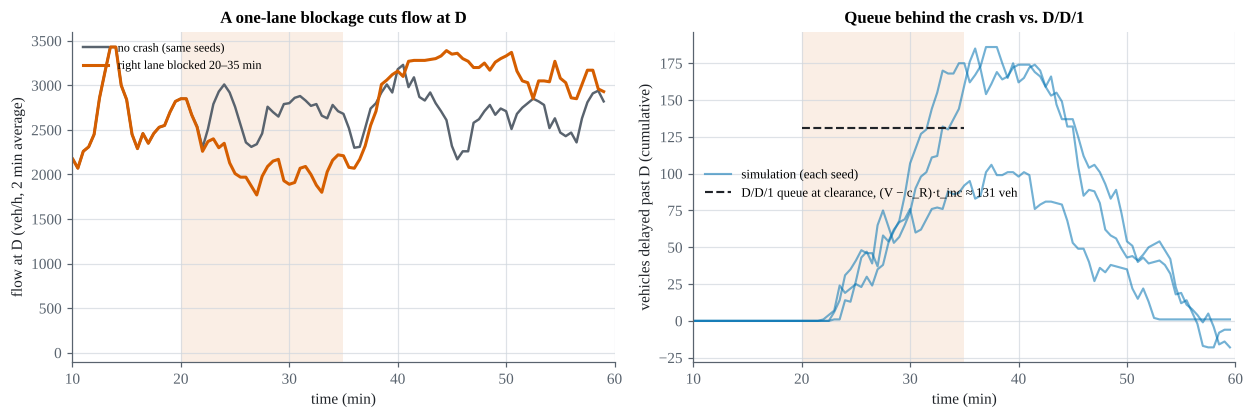

c_R (measured discharge during crash) = 2,175 veh/h; D/D/1 queue = 131 veh; simulated peak deficit = 159 veh


In [13]:
rows, series = [], []
inc = R["inc"]
for i in range(0, len(inc), 2):
    a, b = inc[i], inc[i+1]          # a = with crash, b = same seed without crash
    da, db = st.detectors_df(a), st.detectors_df(b)
    qa = da[da.sensor == "D"].groupby("t0")["count"].sum(); qb = db[db.sensor == "D"].groupby("t0")["count"].sum()
    deficit = (qb.cumsum() - qa.cumsum()).reindex(qa.index).fillna(0)
    ev = a["crash_event"]; bd = [x for x in a["breakdowns"] if x["crash"]]
    rows.append(dict(seed=a["seed"], crash_x_m=ev["x_m"], max_deficit_veh=deficit.max(), discharge_vph=bd[0]["discharge_flow_vph"] if bd else np.nan,
                     drop_pct=bd[0]["capacity_drop_pct"] if bd else np.nan))
    series.append(pd.DataFrame(dict(t_min=qa.index/60, with_crash=qa.values*120, no_crash=qb.reindex(qa.index).values*120, deficit=deficit.values, seed=a["seed"])))
f10 = pd.DataFrame(rows); display(f10.round(1)); f10.to_csv(TAB / "fig13_incident_dd1.csv", index=False)
s = pd.concat(series)
c_R = f10.discharge_vph.mean(); V = 2400 + 300; dd1 = th.dd1_queue(V, c_R, 0.25)
fig, axs = plt.subplots(1, 2, figsize=(11.5, 3.9))
m = s.groupby("t_min")[["with_crash", "no_crash"]].mean().rolling(4, center=True).mean()
axs[0].plot(m.index, m.no_crash, color=MUTED, lw=1.6, label="no crash (same seeds)"); axs[0].plot(m.index, m.with_crash, color=C2, lw=2, label="right lane blocked 20–35 min")
axs[0].axvspan(20, 35, color=C2, alpha=.1, lw=0)
axs[0].set(xlabel="time (min)", ylabel="flow at D (veh/h, 2 min average)", title="A one-lane blockage cuts flow at D", xlim=(10, 60)); axs[0].legend(loc="upper left", fontsize=8)
for sd, g in s.groupby("seed"): axs[1].plot(g.t_min, g.deficit, color=C1, alpha=.55, lw=1.4, label="simulation (each seed)" if sd == 1 else None)
axs[1].hlines(dd1, 20, 35, color=INK, lw=1.4, ls="--", label=f"D/D/1 queue at clearance, (V − c_R)·t_inc ≈ {dd1:.0f} veh")
axs[1].axvspan(20, 35, color=C2, alpha=.1, lw=0)
axs[1].set(xlabel="time (min)", ylabel="vehicles delayed past D (cumulative)", title="Queue behind the crash vs. D/D/1", xlim=(10, 60)); axs[1].legend(loc="upper left", bbox_to_anchor=(0.0, 0.62))
fig.tight_layout(); save(fig, "fig13_incident_dd1"); plt.show()
print(f"c_R (measured discharge during crash) = {c_R:,.0f} veh/h; D/D/1 queue = {dd1:.0f} veh; simulated peak deficit = {f10.max_deficit_veh.mean():.0f} veh")

## Hypothesis sweeps (H1, H2, H4, H6, H7) and the capacity–safety trade-off

These sweeps reproduce and extend Colin's results runs. They live in `reports/midterm/sweeps.py`, which runs each
setting for 3 seeds (4 for the incident) and caches one row per run in `tables/sweep_<name>.csv`. Set `RERUN = True` to
run them again (about 10–15 min on 2 cores); otherwise the cached rows are used.

Every row carries the Section 2.9 measures, counted over the 3,000 s window after warm-up: people delivered at the exit,
TET* (veh·s with TTC < 2 s per 1,000 veh-mi), hard (< −9 ft/s²) and severe (< −15 ft/s²) braking events per 1,000 veh-mi,
and the merge indicators (forced = last 150 ft of the acceleration lane; tight = new follower gap < 20 ft or TTC < 2 s).

In [14]:
sys.path.insert(0, str(REPO / "reports" / "midterm"))
import importlib, sweeps; importlib.reload(sweeps)
RERUN = False
SW = {n: sweeps.load_or_run(n, rerun=RERUN) for n in sweeps.ALL}
CAP2 = 2 * CAP_CODE                      # IDM two-lane capacity, veh/h
PPC = 1.5

def agg(df, by, cols):
    g = df.groupby(by)[cols]
    m, s = g.mean(), g.std()
    return m.join(s, rsuffix="_sd").reset_index()

for n, d in SW.items():
    print(f"{n:9s} {len(d):3d} runs, overlaps {int(d.neg_gaps.sum())}, conservation errors {int(d.main_balance.abs().sum() + d.ramp_balance.abs().sum())}")

demand     18 runs, overlaps 0, conservation errors 0
ramp       15 runs, overlaps 0, conservation errors 0
oneway     39 runs, overlaps 0, conservation errors 0
grid       48 runs, overlaps 0, conservation errors 0
meter      30 runs, overlaps 0, conservation errors 0
incident   12 runs, overlaps 0, conservation errors 0


## Fig 4 — H1 plateau: output versus offered load

saved reports/midterm/figures/fig04_h1_plateau.png


,offered,exited_vph,people_vph,unserved_people,mean_trip_s
0,1400,1351.0,2026.0,44.0,322.0
1,2000,1989.0,2984.0,5.0,360.0
2,2600,2580.0,3871.0,8.0,406.0
3,3200,3164.0,4745.0,31.0,472.0
4,3800,3291.0,4936.0,683.0,539.0
5,4600,3288.0,4932.0,1874.0,533.0


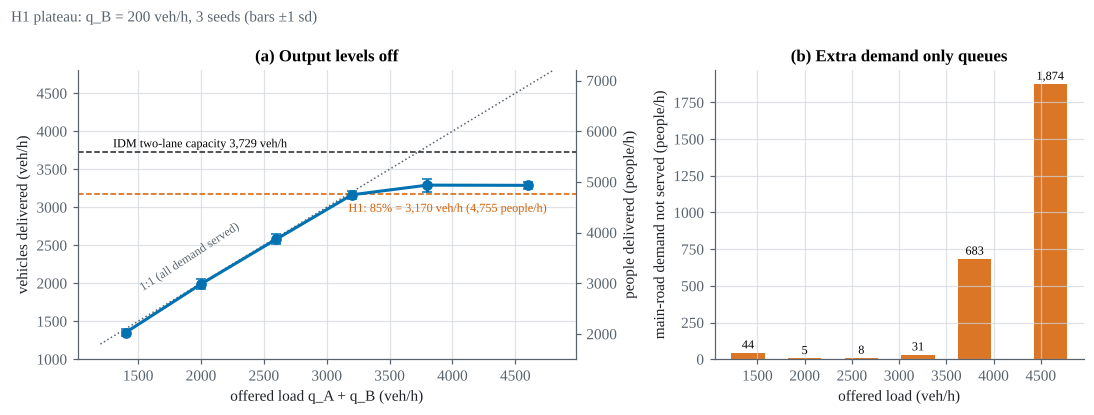

In [15]:
d = SW["demand"].copy(); d["offered"] = d.qA + 200
d["unserved_people"] = PPC * (d.qA - d.flow_A_vph).clip(lower=0)
g = agg(d, "offered", ["exited_vph", "people_vph", "mean_trip_s", "unserved_people", "tet_per_1000vmi"])
fig, axs = plt.subplots(1, 2, figsize=(10, 3.8), gridspec_kw=dict(width_ratios=[1.35, 1]))
ax = axs[0]; x = g.offered
ax.plot([1200, 4800], [1200, 4800], ":", color=MUTED, lw=1); ax.text(1500, 1900, "1:1 (all demand served)", color=MUTED, fontsize=8, rotation=33)
ax.errorbar(x, g.exited_vph, g.exited_vph_sd, fmt="o-", color=C1, lw=2, capsize=3, label="vehicles delivered")
ax.axhline(CAP2, color=INK, lw=1, ls="--"); ax.text(1300, CAP2 + 60, f"IDM two-lane capacity {CAP2:,.0f} veh/h", fontsize=8)
ax.axhline(0.85 * CAP2, color=C2, lw=1, ls="--"); ax.text(4750, 0.85 * CAP2 - 230, f"H1: 85% = {0.85*CAP2:,.0f} veh/h ({0.85*CAP2*PPC:,.0f} people/h)", fontsize=8, color=C2, ha="right")
ax.set(xlabel="offered load q_A + q_B (veh/h)", ylabel="vehicles delivered (veh/h)", title="(a) Output levels off", ylim=(1000, 4800))
sec = ax.secondary_yaxis("right", functions=(lambda v: v * PPC, lambda p: p / PPC)); sec.set_ylabel("people delivered (people/h)")
ax = axs[1]
ax.bar(x, g.unserved_people, width=350, color=C2, alpha=.85)
for xi, yi in zip(x, g.unserved_people): ax.text(xi, yi + 30, f"{yi:,.0f}", ha="center", fontsize=8)
ax.set(xlabel="offered load (veh/h)", ylabel="main-road demand not served (people/h)", title="(b) Extra demand only queues")
fig.suptitle("H1 plateau: q_B = 200 veh/h, 3 seeds (bars ±1 sd)", x=0.01, ha="left", fontsize=10, color=MUTED, fontweight="normal")
fig.tight_layout(); save(fig, "fig04_h1_plateau")
g.round(1).to_csv(TAB / "fig04_h1_plateau.csv", index=False)
display(g[["offered", "exited_vph", "people_vph", "unserved_people", "mean_trip_s"]].round(0))

## Fig 5 — H1 displacement: ramp demand at q_A = 3,200 veh/h

saved reports/midterm/figures/fig05_h1_displacement.png


,qB,main_vph,merged_vph,exited_vph,people_vph,delta,turned_pct,mean_trip_s
0,0,3097.2,0.0,3097.2,4645.8,NaN,NaN,504.82
1,300,2914.4,312.4,3226.8,4840.2,0.59,0.00,522.54
2,600,2338.8,583.2,2922.0,4383.0,2.13,0.00,635.84
3,900,2319.2,585.6,2904.8,4357.2,8.17,28.85,680.13
4,1200,2338.4,586.4,2924.8,4387.2,-24.00,50.55,686.36


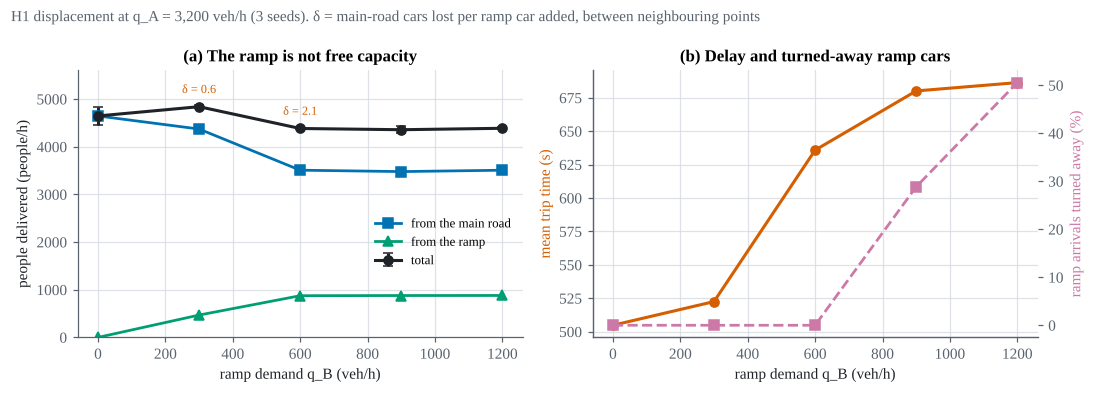

In [16]:
d = SW["ramp"].copy()
d["main_vph"] = d.exited_vph - d.merged_vph
d["turned_pct"] = 100 * d.ramp_turned_away_vph / d.ramp_arrivals_vph.where(d.ramp_arrivals_vph > 0)
g = agg(d, "qB", ["main_vph", "merged_vph", "exited_vph", "people_vph", "mean_trip_s", "turned_pct"])
g["delta"] = -(g.main_vph.diff()) / g.merged_vph.diff()
fig, axs = plt.subplots(1, 2, figsize=(10, 3.6))
ax = axs[0]
ax.errorbar(g.qB, g.people_vph, g.people_vph_sd, fmt="o-", color=INK, lw=2, capsize=3, label="total")
ax.plot(g.qB, g.main_vph * PPC, "s-", color=C1, lw=1.8, label="from the main road")
ax.plot(g.qB, g.merged_vph * PPC, "^-", color=C3, lw=1.8, label="from the ramp")
for xi, yi, dl, dm in zip(g.qB, g.people_vph, g.delta, g.merged_vph.diff()):
    if np.isfinite(dl) and dm > 50:  # only where the ramp actually added cars
        ax.annotate(f"δ = {dl:.1f}", (xi, yi), xytext=(0, 9), textcoords="offset points", ha="center", fontsize=8, color=C2)
ax.set(xlabel="ramp demand q_B (veh/h)", ylabel="people delivered (people/h)", title="(a) The ramp is not free capacity", ylim=(0, 5600)); ax.legend(loc="lower right", bbox_to_anchor=(1, 0.22))
ax = axs[1]
ax.plot(g.qB, g.mean_trip_s, "o-", color=C2, lw=2); ax.set_ylabel("mean trip time (s)", color=C2)
a2 = ax.twinx(); a2.plot(g.qB, g.turned_pct.fillna(0), "s--", color=C4, lw=1.8); a2.set_ylabel("ramp arrivals turned away (%)", color=C4); a2.grid(False)
ax.set(xlabel="ramp demand q_B (veh/h)", title="(b) Delay and turned-away ramp cars")
fig.suptitle("H1 displacement at q_A = 3,200 veh/h (3 seeds). δ = main-road cars lost per ramp car added, between neighbouring points", x=0.01, ha="left", fontsize=10, color=MUTED, fontweight="normal")
fig.tight_layout(); save(fig, "fig05_h1_displacement")
g.round(2).to_csv(TAB / "fig05_h1_displacement.csv", index=False)
display(g[["qB", "main_vph", "merged_vph", "exited_vph", "people_vph", "delta", "turned_pct", "mean_trip_s"]].round(2))

## Fig 6 — H2 time gap: people delivered against conflict exposure

saved reports/midterm/figures/fig06_h2_time_gap.png


,T,people_vph,tet_per_1000vmi,hard_per_1000vmi,severe_per_1000vmi,mean_trip_s
0,0.8,4672.2,2205.2,516.3,26.8,493.9
1,1.0,4399.2,185.4,181.5,28.0,582.9
2,1.5,3793.2,0.0,134.8,27.7,667.1
3,2.0,3280.2,0.0,142.6,36.9,698.1


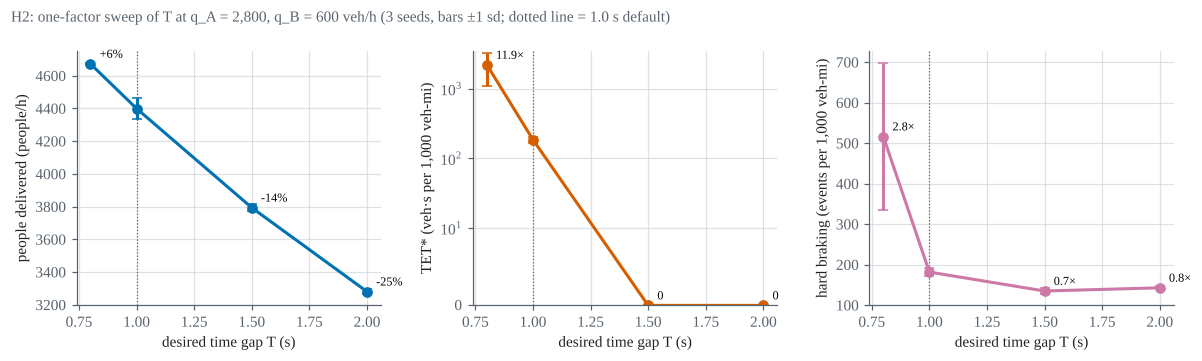

In [17]:
ow = SW["oneway"].copy(); ow["value"] = ow["value"].astype(str)
base = ow[ow.factor == "default"].assign(factor="T", value="1.0")
dT = pd.concat([ow[ow.factor == "T"], base]); dT["T"] = dT.value.astype(float)
MET = ["people_vph", "tet_per_1000vmi", "hard_per_1000vmi", "severe_per_1000vmi", "mean_trip_s"]
gT = agg(dT, "T", MET).sort_values("T")
fig, axs = plt.subplots(1, 3, figsize=(11, 3.3))
for ax, col, lab, c in zip(axs, ["people_vph", "tet_per_1000vmi", "hard_per_1000vmi"],
                           ["people delivered (people/h)", "TET* (veh·s per 1,000 veh-mi)", "hard braking (events per 1,000 veh-mi)"], [C1, C2, C4]):
    ax.errorbar(gT["T"], gT[col], gT[col + "_sd"], fmt="o-", color=c, lw=2, capsize=3)
    ax.axvline(1.0, color=MUTED, lw=.8, ls=":"); ax.set(xlabel="desired time gap T (s)", ylabel=lab)
    b = gT.loc[gT["T"] == 1.0, col].item()
    for xi, yi in zip(gT["T"], gT[col]):
        if xi != 1.0 and b > 0: ax.annotate(f"{(yi/b-1)*100:+.0f}%" if col == "people_vph" else ("0" if yi < 0.05 else f"{yi/b:.1f}×"), (xi, yi), xytext=(6, 4), textcoords="offset points", fontsize=8)
axs[1].set_yscale("symlog", linthresh=10); axs[1].set_ylim(bottom=0)
fig.suptitle("H2: one-factor sweep of T at q_A = 2,800, q_B = 600 veh/h (3 seeds, bars ±1 sd; dotted line = 1.0 s default)", x=0.01, ha="left", fontsize=10, color=MUTED, fontweight="normal")
fig.tight_layout(); save(fig, "fig06_h2_time_gap")
gT.round(1).to_csv(TAB / "fig06_h2_time_gap.csv", index=False); display(gT[["T"] + MET].round(1))

## Fig 8 — H4: meter wait at q_B = 900 veh/h

saved reports/midterm/figures/fig08_h4_meter_sweep.png


,qA,meter,people_vph,merged_vph,turned_pct,tet_per_1000vmi,hard_per_1000vmi,mean_trip_s,gain_pct
0,2800,2,4339.8,587.2,28.2,193.7,177.9,627.0,0.0
1,2800,6,4357.2,582.0,35.6,178.1,177.0,561.5,0.4
2,2800,8,4674.0,442.8,50.4,74.7,269.4,470.8,7.7
3,2800,12,4607.4,296.8,66.9,43.5,215.8,460.1,6.2
4,2800,20,4329.0,178.8,79.4,5.8,174.1,441.1,-0.2
5,3200,2,4357.2,585.6,28.9,198.8,160.8,680.1,0.0
6,3200,6,4370.4,580.8,36.2,179.2,164.2,614.5,0.3
7,3200,8,4810.2,444.4,52.0,177.6,231.3,569.4,10.4
8,3200,12,4842.6,297.2,67.2,78.9,190.8,520.6,11.1
9,3200,20,4859.4,178.0,80.1,34.8,149.8,514.8,11.5


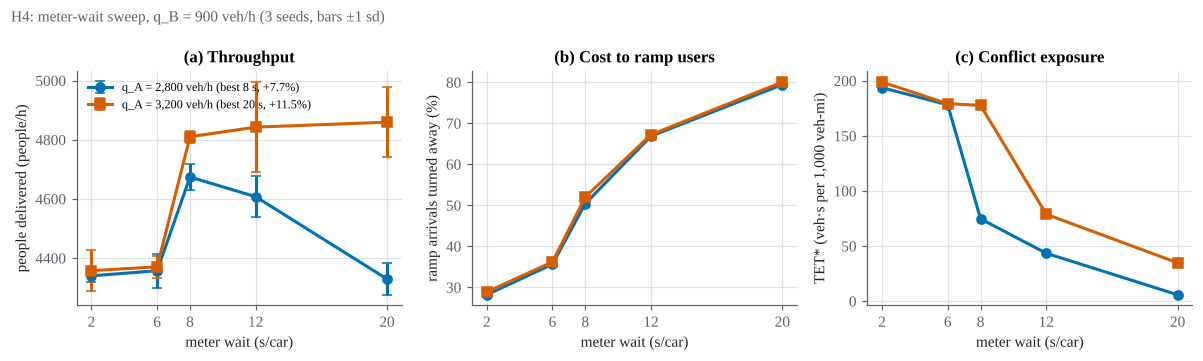

In [18]:
d = SW["meter"].copy()
d["turned_pct"] = 100 * d.ramp_turned_away_vph / d.ramp_arrivals_vph
g8 = agg(d, ["qA", "meter"], ["people_vph", "merged_vph", "turned_pct", "tet_per_1000vmi", "hard_per_1000vmi", "mean_trip_s"])
g8["gain_pct"] = g8.groupby("qA").people_vph.transform(lambda s: (s / s.iloc[0] - 1) * 100)
fig, axs = plt.subplots(1, 3, figsize=(11, 3.3))
for (q, gg), c, mk in zip(g8.groupby("qA"), [C1, C2], ["o", "s"]):
    best = gg.loc[gg.people_vph.idxmax()]
    axs[0].errorbar(gg.meter, gg.people_vph, gg.people_vph_sd, fmt=mk + "-", color=c, lw=2, capsize=3, label=f"q_A = {q:,} veh/h (best {best.meter:.0f} s, {best.gain_pct:+.1f}%)")
    axs[1].plot(gg.meter, gg.turned_pct, mk + "-", color=c, lw=2)
    axs[2].plot(gg.meter, gg.tet_per_1000vmi, mk + "-", color=c, lw=2)
axs[0].legend(loc="upper left", fontsize=8); axs[0].set(xlabel="meter wait (s/car)", ylabel="people delivered (people/h)", title="(a) Throughput")
axs[1].set(xlabel="meter wait (s/car)", ylabel="ramp arrivals turned away (%)", title="(b) Cost to ramp users")
axs[2].set(xlabel="meter wait (s/car)", ylabel="TET* (veh·s per 1,000 veh-mi)", title="(c) Conflict exposure")
for ax in axs: ax.set_xticks([2, 6, 8, 12, 20])
fig.suptitle("H4: meter-wait sweep, q_B = 900 veh/h (3 seeds, bars ±1 sd)", x=0.01, ha="left", fontsize=10, color=MUTED, fontweight="normal")
fig.tight_layout(); save(fig, "fig08_h4_meter_sweep")
g8.round(1).to_csv(TAB / "fig08_h4_meter.csv", index=False); display(g8.drop(columns=[c for c in g8 if c.endswith("_sd")]).round(1))

## Fig 10 — H6: lane-change rule and geometry

saved reports/midterm/figures/fig10_h6_lane_change_geometry.png


,factor,x,people_vph,tet_per_1000vmi,hard_per_1000vmi,severe_per_1000vmi,mean_trip_s
0,bsafe,6.0,4414.2,104.1,72.8,33.4,537.9
1,bsafe,9.0,4400.4,148.5,72.8,33.8,554.3
2,bsafe,13.0,4399.2,185.4,181.5,28.0,582.9
3,bsafe,20.0,4386.0,233.1,236.4,82.2,594.8
4,rampm,2000.0,4399.2,131.2,167.2,30.8,574.5
5,rampm,2500.0,4399.2,185.4,181.5,28.0,582.9
6,rampm,3000.0,4380.6,236.3,182.2,31.7,573.1
7,rlen,200.0,4425.0,164.2,179.1,30.8,576.6
8,rlen,400.0,4399.2,185.4,181.5,28.0,582.9
9,rlen,700.0,4420.2,182.7,169.5,30.9,573.5


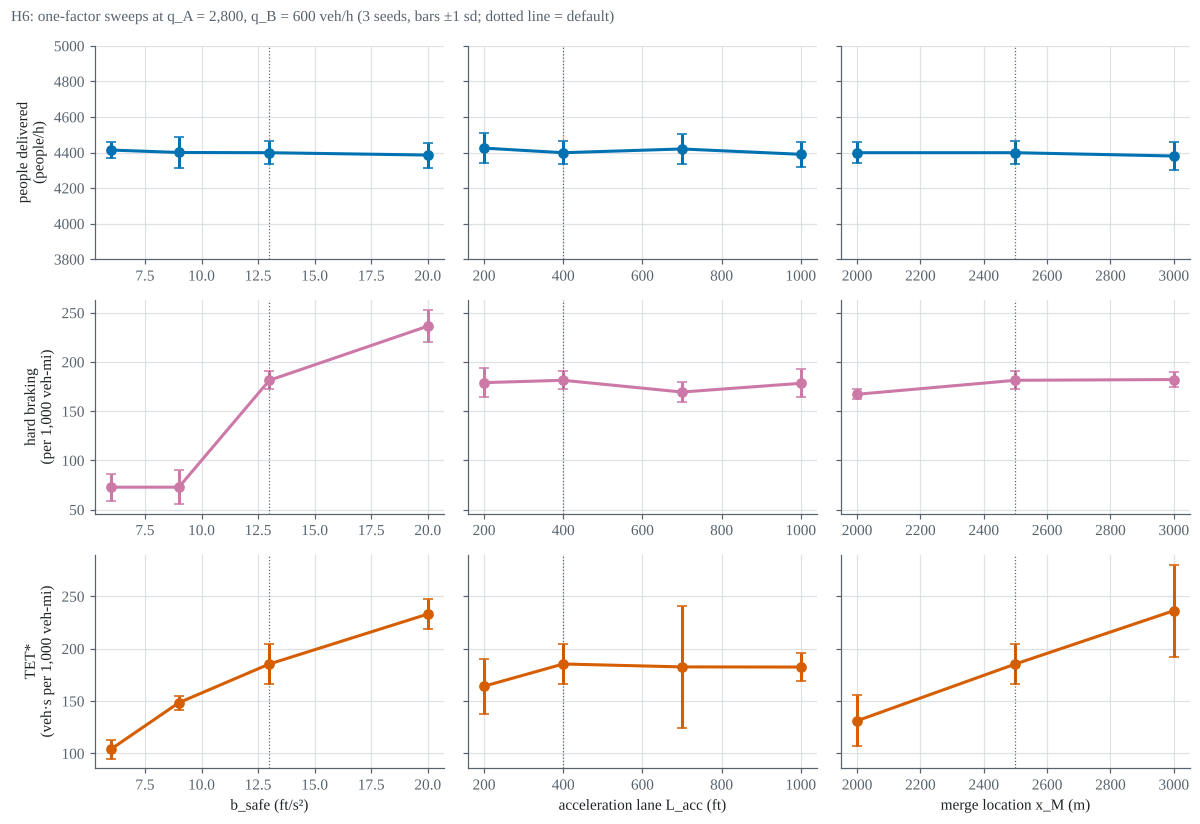

In [19]:
rows = {"bsafe": ("b_safe (ft/s²)", 13), "rlen": ("acceleration lane L_acc (ft)", 400), "rampm": ("merge location x_M (m)", 2500)}
parts = []
for f, (lab, dv) in rows.items():
    x = pd.concat([ow[ow.factor == f], base.assign(factor=f, value=str(dv))]); x["x"] = x.value.astype(float); parts.append(x)
g10 = agg(pd.concat(parts), ["factor", "x"], MET)
fig, axs = plt.subplots(3, 3, figsize=(11, 7.6), sharey="row")
for j, (f, (lab, dv)) in enumerate(rows.items()):
    gg = g10[g10.factor == f].sort_values("x")
    for i, (col, ylab, c) in enumerate([("people_vph", "people delivered\n(people/h)", C1), ("hard_per_1000vmi", "hard braking\n(per 1,000 veh-mi)", C4),
                                        ("tet_per_1000vmi", "TET*\n(veh·s per 1,000 veh-mi)", C2)]):
        ax = axs[i, j]; ax.errorbar(gg.x, gg[col], gg[col + "_sd"], fmt="o-", color=c, lw=2, capsize=3)
        ax.axvline(dv, color=MUTED, lw=.8, ls=":")
        if j == 0: ax.set_ylabel(ylab)
        if i == 2: ax.set_xlabel(lab)
        if i == 0: ax.set_ylim(3800, 5000)
fig.suptitle("H6: one-factor sweeps at q_A = 2,800, q_B = 600 veh/h (3 seeds, bars ±1 sd; dotted line = default)", x=0.01, ha="left", fontsize=10, color=MUTED, fontweight="normal")
fig.tight_layout(); save(fig, "fig10_h6_lane_change_geometry")
g10.round(1).to_csv(TAB / "fig10_h6.csv", index=False); display(g10[["factor", "x"] + MET].round(1))

## Fig 11 — H6: acceleration-lane length × meter wait grid

saved reports/midterm/figures/fig11_h6_grid.png
people/h range 4,389–4,449 (1.4%); seed sd 36–89; forced merges 100–100%, tight 94–98%


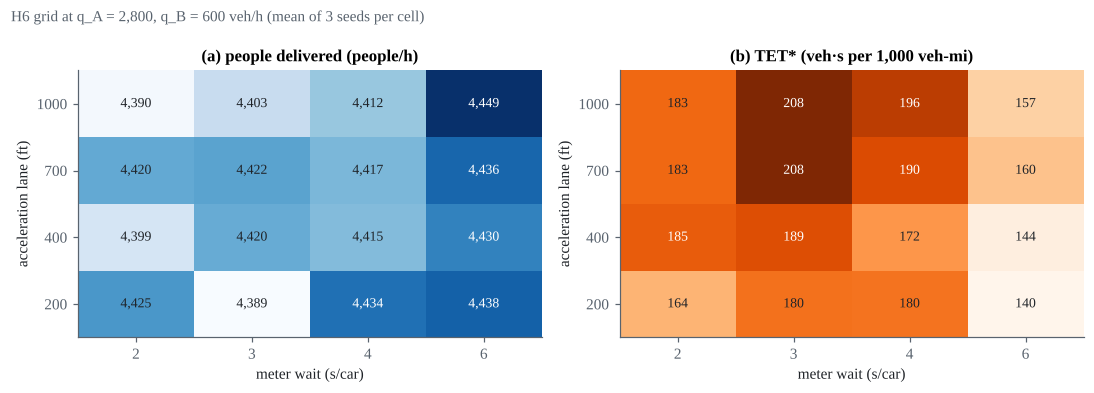

In [20]:
gr = agg(SW["grid"], ["rlen", "meter"], ["people_vph", "tet_per_1000vmi", "forced_pct", "tight_pct"])
fig, axs = plt.subplots(1, 2, figsize=(10, 3.6))
for ax, col, cmap, ttl in zip(axs, ["people_vph", "tet_per_1000vmi"], ["Blues", "Oranges"], ["(a) people delivered (people/h)", "(b) TET* (veh·s per 1,000 veh-mi)"]):
    m = gr.pivot(index="rlen", columns="meter", values=col).sort_index(ascending=False)
    im = ax.imshow(m.values, cmap=cmap, aspect="auto")
    for (i, j), v in np.ndenumerate(m.values):
        ax.text(j, i, f"{v:,.0f}", ha="center", va="center", fontsize=9, color="white" if v > np.nanmean(m.values) + 0.4 * np.nanstd(m.values) else INK)
    ax.set_xticks(range(m.shape[1]), m.columns); ax.set_yticks(range(m.shape[0]), m.index); ax.grid(False)
    ax.set(xlabel="meter wait (s/car)", ylabel="acceleration lane (ft)", title=ttl)
fig.suptitle("H6 grid at q_A = 2,800, q_B = 600 veh/h (mean of 3 seeds per cell)", x=0.01, ha="left", fontsize=10, color=MUTED, fontweight="normal")
fig.tight_layout(); save(fig, "fig11_h6_grid")
gr.round(1).to_csv(TAB / "fig11_h6_grid.csv", index=False)
print(f"people/h range {gr.people_vph.min():,.0f}–{gr.people_vph.max():,.0f} ({(gr.people_vph.max()/gr.people_vph.min()-1)*100:.1f}%); "
      f"seed sd {gr.people_vph_sd.min():.0f}–{gr.people_vph_sd.max():.0f}; forced merges {gr.forced_pct.min():.0f}–{gr.forced_pct.max():.0f}%, tight {gr.tight_pct.min():.0f}–{gr.tight_pct.max():.0f}%")

## Fig 12 — H7: people delivered with a one-lane crash

saved reports/midterm/figures/fig12_h7_incident.png


,clear_h,people_vph,people_vph_sd
0,0.0,3458.0,67.0
1,0.0,3456.0,67.0
2,0.0,3059.0,214.0


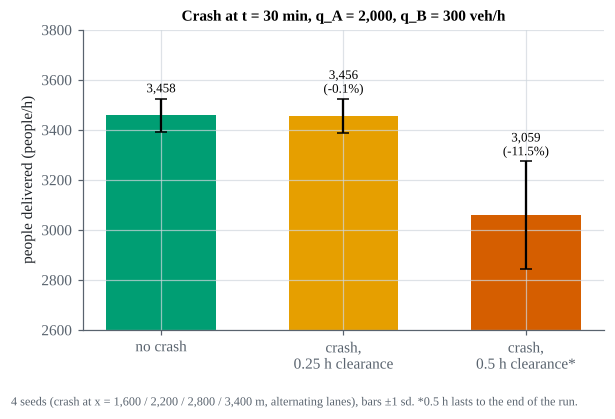

In [21]:
d = SW["incident"]
g12 = agg(d, "clear_h", ["people_vph"])
fig, ax = plt.subplots(figsize=(5.6, 3.6))
labs = {0: "no crash", 0.25: "crash,\n0.25 h clearance", 0.5: "crash,\n0.5 h clearance*"}
cols = [C3, C5, C2]
ax.bar(range(len(g12)), g12.people_vph, yerr=g12.people_vph_sd, color=cols, capsize=4, width=.6)
b0 = g12.people_vph.iloc[0]
for i, v in enumerate(g12.people_vph): ax.text(i, v + g12.people_vph_sd.iloc[i] + 25, f"{v:,.0f}" + ("" if i == 0 else f"\n({(v/b0-1)*100:+.1f}%)"), ha="center", fontsize=8.5)
ax.set_xticks(range(len(g12)), [labs[c] for c in g12.clear_h]); ax.set_ylim(2600, 3800); ax.set_ylabel("people delivered (people/h)")
ax.set_title("Crash at t = 30 min, q_A = 2,000, q_B = 300 veh/h", fontsize=10)
fig.text(0.01, -0.04, "4 seeds (crash at x = 1,600 / 2,200 / 2,800 / 3,400 m, alternating lanes), bars ±1 sd. *0.5 h lasts to the end of the run.", fontsize=8, color=MUTED)
fig.tight_layout(); save(fig, "fig12_h7_incident")
g12.round(1).to_csv(TAB / "fig12_h7_incident.csv", index=False); display(g12.round(0))

## Fig 17 — Capacity versus conflict exposure for every design tested

saved reports/midterm/figures/fig17_tradeoff_frontier.png


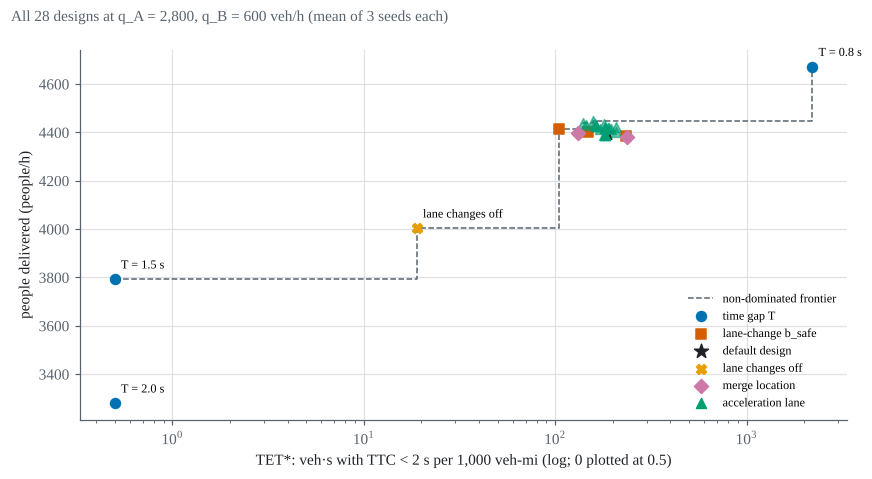

In [22]:
des = pd.concat([ow.assign(group=ow.factor), SW["grid"].assign(group="grid", factor="grid", value=SW["grid"].rlen.astype(str) + " ft, " + SW["grid"].meter.astype(str) + " s")])
gd = des.groupby(["group", "value"])[["people_vph", "tet_per_1000vmi"]].mean().reset_index()
gd = gd[~((gd.group == "grid") & (gd.value == "400 ft, 2 s"))]          # same as the default design
# non-dominated frontier: more people and less TET*
srt = gd.sort_values(["tet_per_1000vmi", "people_vph"], ascending=[True, False]); front, best = [], -np.inf
for _, r in srt.iterrows():
    if r.people_vph > best: front.append(r); best = r.people_vph
front = pd.DataFrame(front)
sty = {"default": ("*", INK, "default design"), "T": ("o", C1, "time gap T"), "bsafe": ("s", C2, "lane-change b_safe"),
       "rlen": ("^", C3, "acceleration lane"), "rampm": ("D", C4, "merge location"), "grid": ("^", C3, None), "lc": ("X", C5, "lane changes off")}
fig, ax = plt.subplots(figsize=(8, 4.4))
ax.step(front.tet_per_1000vmi.clip(lower=0.5), front.people_vph, where="post", color=MUTED, ls="--", lw=1, label="non-dominated frontier")
for grp, gg in gd.groupby("group"):
    m, c, lab = sty[grp]; ax.scatter(gg.tet_per_1000vmi.clip(lower=0.5), gg.people_vph, marker=m, color=c, s=90 if grp == "default" else 42, label=lab, zorder=3, alpha=.6 if grp == "grid" else 1)
for _, r in gd[gd.group.isin(["T", "lc"])].iterrows():
    ax.annotate(f"T = {r.value} s" if r.group == "T" else "lane changes off", (max(r.tet_per_1000vmi, .5), r.people_vph), xytext=(4, 7), textcoords="offset points", fontsize=8)
ax.set_xscale("log"); ax.set(xlabel="TET*: veh·s with TTC < 2 s per 1,000 veh-mi (log; 0 plotted at 0.5)", ylabel="people delivered (people/h)")
h, l = ax.get_legend_handles_labels(); keep = [(a, b) for a, b in zip(h, l) if b and not b.startswith("_")]
ax.legend(*zip(*keep), loc="lower right", fontsize=8)
fig.suptitle(f"All {len(gd)} designs at q_A = 2,800, q_B = 600 veh/h (mean of 3 seeds each)", x=0.01, ha="left", fontsize=10, color=MUTED, fontweight="normal")
fig.tight_layout(); save(fig, "fig17_tradeoff_frontier")
gd.round(1).to_csv(TAB / "fig17_designs.csv", index=False)

## Key numbers from the hypothesis sweeps

In [23]:
gb = lambda f, v: gT.set_index("T").loc[v] if f == "T" else g10.set_index(["factor", "x"]).loc[(f, v)]
d0 = gT.set_index("T").loc[1.0]
lc = ow[ow.factor == "lc"][MET].mean()
inc = g12.set_index("clear_h").people_vph
dem = SW["demand"].groupby("qA")[["exited_vph", "people_vph"]].mean()
KN2 = {
  "H1 plateau veh/h at q_A 3,600 / 4,400": dem.exited_vph.loc[[3600, 4400]].round(0).tolist(),
  "H1 plateau people/h": dem.people_vph.loc[[3600, 4400]].round(0).tolist(),
  "H1 plateau share of two-lane capacity %": (100 * dem.exited_vph.loc[[3600, 4400]] / CAP2).round(1).tolist(),
  "H1 delta by ramp step": pd.read_csv(TAB / "fig05_h1_displacement.csv").set_index("qB").delta.round(2).to_dict(),
  "H2 T=0.8 people change %": round((gT.set_index('T').loc[0.8].people_vph / d0.people_vph - 1) * 100, 1),
  "H2 T=0.8 TET* ratio": round(gT.set_index('T').loc[0.8].tet_per_1000vmi / d0.tet_per_1000vmi, 1),
  "H2 T=1.5 people change %": round((gT.set_index('T').loc[1.5].people_vph / d0.people_vph - 1) * 100, 1),
  "H2 T=2.0 people change %": round((gT.set_index('T').loc[2.0].people_vph / d0.people_vph - 1) * 100, 1),
  "H6 b_safe 6 hard-braking change %": round((gb('bsafe', 6.0).hard_per_1000vmi / d0.hard_per_1000vmi - 1) * 100, 1),
  "H6 b_safe 6 people change %": round((gb('bsafe', 6.0).people_vph / d0.people_vph - 1) * 100, 1),
  "H6 geometry people range %": [round((gb(f, v).people_vph / d0.people_vph - 1) * 100, 1) for f, v in [("rlen", 200.0), ("rlen", 700.0), ("rlen", 1000.0), ("rampm", 2000.0), ("rampm", 3000.0)]],
  "lane changes off people change %": round((lc.people_vph / d0.people_vph - 1) * 100, 1),
  "lane changes off TET* change %": round((lc.tet_per_1000vmi / d0.tet_per_1000vmi - 1) * 100, 1),
  "H4 best gain % by q_A": g8.loc[g8.groupby("qA").people_vph.idxmax(), ["qA", "meter", "gain_pct"]].round(1).values.tolist(),
  "H7 change % 0.25 h / 0.5 h": [round((inc.loc[0.25] / inc.loc[0] - 1) * 100, 1), round((inc.loc[0.5] / inc.loc[0] - 1) * 100, 1)],
}
for k, v in KN2.items(): print(f"{k}: {v}")
pd.Series({k: str(v) for k, v in KN2.items()}).to_csv(TAB / "key_numbers_sweeps.csv", header=["value"])

H1 plateau veh/h at q_A 3,600 / 4,400: [3291.0, 3288.0]
H1 plateau people/h: [4936.0, 4932.0]
H1 plateau share of two-lane capacity %: [88.2, 88.2]
H1 delta by ramp step: {0: nan, 300: 0.59, 600: 2.13, 900: 8.17, 1200: -24.0}
H2 T=0.8 people change %: 6.2
H2 T=0.8 TET* ratio: 11.9
H2 T=1.5 people change %: -13.8
H2 T=2.0 people change %: -25.4
H6 b_safe 6 hard-braking change %: -59.9
H6 b_safe 6 people change %: 0.3
H6 geometry people range %: [np.float64(0.6), np.float64(0.5), np.float64(-0.2), np.float64(0.0), np.float64(-0.4)]
lane changes off people change %: -9.0
lane changes off TET* change %: -89.8
H4 best gain % by q_A: [[2800.0, 8.0, 7.7], [3200.0, 20.0, 11.5]]
H7 change % 0.25 h / 0.5 h: [np.float64(-0.1), np.float64(-11.5)]


## Key numbers for the report text

In [24]:
m6 = f6.groupby(["T", "qB"]).unserved_pct.mean()
key = {
    "IDM capacity, code values, T=1.0 (veh/h/lane)": round(CAP_CODE),
    "IDM capacity, code values, T=1.5 (veh/h/lane)": round(cap15),
    "H1 predicted q_B* (veh/h)": round(pred[1.0]), "H2 predicted q_B* (veh/h)": round(pred[1.5]),
    "H1 unserved % by q_B": m6.loc[1.0].round(1).to_dict(), "H2 unserved % by q_B": m6.loc[1.5].round(1).to_dict(),
    "Max flow at D, T=1.0 (veh/h)": round(f6[f6["T"] == 1.0].groupby("qB").flow_D_vph.mean().max()),
    "Max flow at D, T=1.5 (veh/h)": round(f6[f6["T"] == 1.5].groupby("qB").flow_D_vph.mean().max()),
    "Wave speeds (km/h)": np.round(w_kmh, 1).tolist(),
    "Pulse ratio (median by flow), code": f7[f7.params == "code values"].groupby("flow").ratio.median().round(2).to_dict(),
    "Pulse ratio (median by flow), Lecture 04 values": f7[f7.params == "Lecture 04 values"].groupby("flow").ratio.median().round(2).to_dict(),
    "M/D/1 error % by row": g3.err_pct.round(1).tolist(),
    "H5 flow at D by v0": g9.flow_D_vph.round(0).to_dict(), "H5 gain % measured": g9.throughput_gain_pct.round(1).to_dict(),
    "H5 gain % theory": g9.capacity_gain_pct.round(1).to_dict(), "H5 trip speed mph": g9.trip_speed_mph.round(1).to_dict(),
    "Incident: discharge c_R (veh/h)": round(c_R), "Incident: D/D/1 queue (veh)": round(dd1), "Incident: simulated deficit (veh)": round(f10.max_deficit_veh.mean()),
    "Incident: capacity drop %": round(f10.drop_pct.mean(), 1),
}
for k, v in key.items(): print(f"{k}: {v}")
pd.Series({k: str(v) for k, v in key.items()}).to_csv(TAB / "key_numbers.csv")
print(f"\nTotal runtime {time.time() - T0:.0f} s")

IDM capacity, code values, T=1.0 (veh/h/lane): 1865
IDM capacity, code values, T=1.5 (veh/h/lane): 1447
H1 predicted q_B* (veh/h): 665
H2 predicted q_B* (veh/h): 247
H1 unserved % by q_B: {300: 0.5, 450: 1.2, 600: 4.9, 750: 7.5, 900: 12.0, 1200: 19.2}
H2 unserved % by q_B: {0: 0.2, 150: 1.9, 300: 3.4, 450: 9.9, 600: 16.7, 900: 24.1}
Max flow at D, T=1.0 (veh/h): 2912
Max flow at D, T=1.5 (veh/h): 2608
Wave speeds (km/h): [-18.3, -19.1, -18.3, -19.1, -18.3, -19.1]
Pulse ratio (median by flow), code: {1200: 0.8, 2400: 0.65, 3200: 0.87}
Pulse ratio (median by flow), Lecture 04 values: {1200: 0.04, 2400: 0.87, 3200: 0.87}
M/D/1 error % by row: [0.2, 5.6, 17.8]
H5 flow at D by v0: {35: 3127.0, 55: 3366.0, 75: 3476.0}
H5 gain % measured: {35: 0.0, 55: 7.6, 75: 11.2}
H5 gain % theory: {35: 0.0, 55: 16.7, 75: 27.0}
H5 trip speed mph: {35: 14.8, 55: 20.7, 75: 22.9}
Incident: discharge c_R (veh/h): 2175
Incident: D/D/1 queue (veh): 131
Incident: simulated deficit (veh): 159
Incident: capacity dr